In [1]:
# ===========================================================================
# Bibliotheken
# ===========================================================================
# Alle teamleden gebruiken exact dezelfde versies (zie requirements.txt), zodat
# de resultaten reproduceerbaar en onderling vergelijkbaar zijn.
from typing import Any

# --- Data en visualisatie ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Hulptools ---
import optuna

# --- Scikit-learn: bouwstenen ---
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV  # kanscalibratie voor SVM
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# --- Scikit-learn: modellen ---
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

# --- Externe modellen en imbalance-technieken ---
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline  # pipeline die SMOTE ondersteunt
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler  # undersampling-variant voor KNN

# Één vaste random_state voor het hele project. Dezelfde waarde voor alle
# teamleden betekent: dezelfde train/validatiesplit en dus vergelijkbare scores.
RANDOM_STATE = 42

# Opdracht 1: Voorspel Herseninfarct (Stroke Prediction)

**Competitie:** Predicting stroke 2026-27 | Kaggle  
**Teamnaam:** Groep 4  
**Teamleden & Kaggle Usernames:**
- Kaman - [Kaggle Username: KMT250]
- Alex - [Kaggle Username: Alex Gaiser 2]
- Pablo - [Kaggle Username: Artheriax]

---

## 1. Inleiding

In dit project werken we als junior data scientists bij *MedPredict*. Het doel is om een
machine learning model te ontwikkelen dat op basis van demografische, leefstijl- en
medische gegevens kan voorspellen of een patiënt een verhoogd risico loopt op een
herseninfarct (stroke). Dit model ondersteunt zorgprofessionals bij preventie en
gerichte opvolging.

**Opbouw van dit notebook**

| Sectie | Inhoud |
|--------|--------|
| 1 | Inleiding |
| 2 | Data en exploratieve data-analyse (EDA) |
| 3 | Data opschonen en voorbereiden |
| 4 | Evaluatie: metrics, de F1-score en het vaste tabelformat (Opdracht 2) |
| 5 | Modeltraining: vaste werkwijze voor alle modellen |
| 6 | Modellen: KNN en Logistic Regression, SVM, Decision Tree en de boom-ensembles (Opdracht 3) |
| 7 | Zelf samengesteld ensemble 1: Random Forest + GBDT + XGBoost |
| 8 | Tweede zelf samengesteld ensemble: SVM + Random Forest + Logistic Regression |
| 9 | Conclusie en advies met de eindtabel van alle modellen (Opdracht 4) |
| 10 | Submissions genereren voor Kaggle |
| 11 | Bronnen en AI-verantwoording |

Alle teamleden gebruiken dezelfde `random_state` (42), dezelfde train/validatiesplit en
dezelfde F1-score. Daardoor kunnen we de modellen eerlijk met elkaar vergelijken.

## 2. Data en exploratieve data-analyse (EDA)

### 2.1 Uitleg van de kolommen

De dataset bevat al numerieke waarden en dummyvariabelen. De kolommen betekenen:
- **id**: unieke identificatie van de patiënt. Deze kolom wordt niet als voorspeller gebruikt.
- **age**: leeftijd van de patiënt in jaren.
- **hypertension**: indicator voor hoge bloeddruk; 0 = nee, 1 = ja.
- **heart_disease**: indicator voor hartziekte; 0 = nee, 1 = ja.
- **avg_glucose_level**: gemiddeld glucosegehalte in het bloed.
- **bmi**: Body Mass Index, een maat voor gewicht in verhouding tot lengte.
- **gender_Female**, **gender_Male**, **gender_Other**: dummyvariabelen voor het geregistreerde geslacht.
- **ever_married_No**, **ever_married_Yes**: dummyvariabelen voor de burgerlijke staat.
- **work_type_Govt_job**, **work_type_Never_worked**, **work_type_Private**, **work_type_Self-employed**, **work_type_children**: dummyvariabelen voor het soort werk.
- **Residence_type_Rural**, **Residence_type_Urban**: dummyvariabelen voor het type woonomgeving.
- **smoking_status_formerly smoked**, **smoking_status_never smoked**, **smoking_status_smokes**: dummyvariabelen voor rookstatus. Patiënten met rookstatus 'unknown' hebben op alle drie deze kolommen een 0 (referentiecategorie).
- **stroke**: doelvariabele; 1 betekent dat de patiënt een herseninfarct heeft gehad en 0 dat niet. Deze kolom ontbreekt in `test.csv`.

In [2]:
def converteer_bool_kolommen(df: pd.DataFrame) -> pd.DataFrame:
    """
    Zet alle kolommen met dtype `bool` om naar 0/1.

    Waarom? De dummyvariabelen (gender, work_type, ...) staan in het
    CSV-bestand als True/False. Sommige sklearn- en XGBoost-versies gaan daar
    niet goed mee om, terwijl 0/1 altijd werkt. Deze functie staat bewust op
    één plek (DRY) en wordt gebruikt door zowel de ruwe inlaadstap hieronder
    als de gedeelde laadfunctie `load_stroke_data` in §3.4.
    """
    for kolom in df.select_dtypes(include=['bool']).columns:
        df[kolom] = df[kolom].astype(int)
    return df


class DataLoader:
    """
    Laadt de ruwe train- en testdataset in voor de EDA.

    Twee dingen worden hier geregeld:
    1. Inlezen van de CSV-bestanden (met header, dus de standaard header=0).
    2. Omzetten van kolommen met dtype `bool` naar 0/1
       (via `converteer_bool_kolommen`).

    De omzetting gebeurt voor train en test afzonderlijk, maar met dezelfde
    kolomnamen, zodat de kolomvolgorde in beide datasets identiek blijft.
    """

    def __init__(self, train_path, test_path):
        self.train_path = train_path
        self.test_path = test_path

    def load_data(self):
        """Laadt de train- en testdataset en converteert booleans naar 0/1."""
        self.train_df = converteer_bool_kolommen(pd.read_csv(self.train_path))
        self.test_df = converteer_bool_kolommen(pd.read_csv(self.test_path))
        return self.train_df, self.test_df


# Inladen van de data
loader = DataLoader('train.csv', 'test.csv')
train_df, test_df = loader.load_data()

# Controle: klopt het aantal rijen en kolommen met wat we verwachten?
# train.csv bevat ook de doelvariabele `stroke`, test.csv niet.
print("Train Data Shape:", train_df.shape)
print("Test Data Shape:", test_df.shape)
train_df.head()

Train Data Shape: (33550, 22)
Test Data Shape: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0
1,72295,75.0,1,0,215.17,48.0,1,0,0,0,...,0,0,1,0,1,0,0,1,0,0
2,26451,15.0,0,0,135.22,19.0,0,1,0,1,...,0,1,0,0,1,0,0,1,0,0
3,65210,47.0,0,0,64.89,28.2,0,1,0,0,...,0,0,1,0,0,1,0,1,0,0
4,69299,49.0,0,0,222.34,28.8,0,1,0,0,...,0,0,1,0,1,0,1,0,0,0


In [3]:
# Eerste blik op de zojuist ingelezen trainingsdata: het aantal niet-null
# waarden per kolom (zo zie je meteen of er ontbrekende waarden zijn, bij
# `bmi` bijvoorbeeld) en de datatypes die de modellen straks te zien krijgen.
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  int64  
 7   gender_Male                     33550 non-null  int64  
 8   gender_Other                    33550 non-null  int64  
 9   ever_married_No                 33550 non-null  int64  
 10  ever_married_Yes                33550 non-null  int64  
 11  work_type_Govt_job              33550 non-null  int64  
 12  work_type_Never_worked          33550 non-n

### 2.2 Minimale vereisten voor machine learning met scikit-learn

Scikit-learn verwacht dat de invoervariabelen numeriek zijn en dat het gekozen algoritme
met ontbrekende waarden kan omgaan. De dummyvariabelen worden daarom bij het inladen
omgezet van True/False naar 0 en 1. In onze dataset zijn geen ontbrekende BMI-waarden
gevonden. Toch laten we de imputatiestap in de pipeline staan, omdat die de code robuuster
maakt als een vergelijkbare dataset later wel ontbrekende waarden bevat.

De dataset bevat 33.550 patiënten. Daarvan hebben 517 patiënten `stroke = 1` en 33.033
patiënten `stroke = 0`. Het positieve aandeel is ongeveer 1,54%, dus de dataset is sterk
imbalanced. De kolom `id` is alleen een identificatienummer en wordt daarom niet als
voorspeller gebruikt.

### 2.3 Datatypes en basisstatistieken

In [4]:
def show_basic_stats(df):
    """
    Toont datatypes, samenvattende statistieken en ontbrekende waarden.

    Doel van deze functie is het beantwoorden van de minimale vereisten uit de
    opdracht:
    - Zijn alle kolommen numeriek (of op zijn minst bruikbaar)? -> dtypes-overzicht
    - Wat is de schaal van de variabelen? -> describe(), nodig om te bepalen of
      standaardisatie zin heeft (een kolom met waarden rond 100 domineert anders
      een kolom met waarden rond 0,5).
    - Zijn er ontbrekende waarden? -> isnull().sum(); die moeten later geïmputeerd
      worden, anders weigert het model te trainen.
    """
    print("--- Data Types ---")
    print(df.dtypes.value_counts())

    print("\n--- Basisstatistieken ---")
    display(df.describe())

    # Check voor missing values: som over alle kolommen. Alleen kolommen met
    # daadwerkelijk ontbrekende waarden worden getoond, anders wordt de output
    # onnodig lang.
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\n--- Missing Values ---")
        print(missing[missing > 0])
    else:
        print("\nGeen missing values gevonden in de basisinspectie.")


show_basic_stats(train_df)

--- Data Types ---
int64      19
float64     3
Name: count, dtype: int64

--- Basisstatistieken ---


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,...,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.597079,0.402742,0.000179,0.361371,...,0.004203,0.574635,0.152787,0.144501,0.499970,0.500030,0.168733,0.375618,0.148048,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.490492,0.490457,0.013372,0.480405,...,0.064693,0.494406,0.359787,0.351602,0.500007,0.500007,0.374522,0.484289,0.355153,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,1.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,1.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Geen missing values gevonden in de basisinspectie.


### 2.4 Relaties tussen variabelen (visualisaties)

We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (`stroke`).
Eerst met boxplots voor de continue variabelen, daarna met een correlatiematrix voor de
kernvariabelen. Dit bepaalt welke variabelen waarschijnlijk voorspellend zijn.

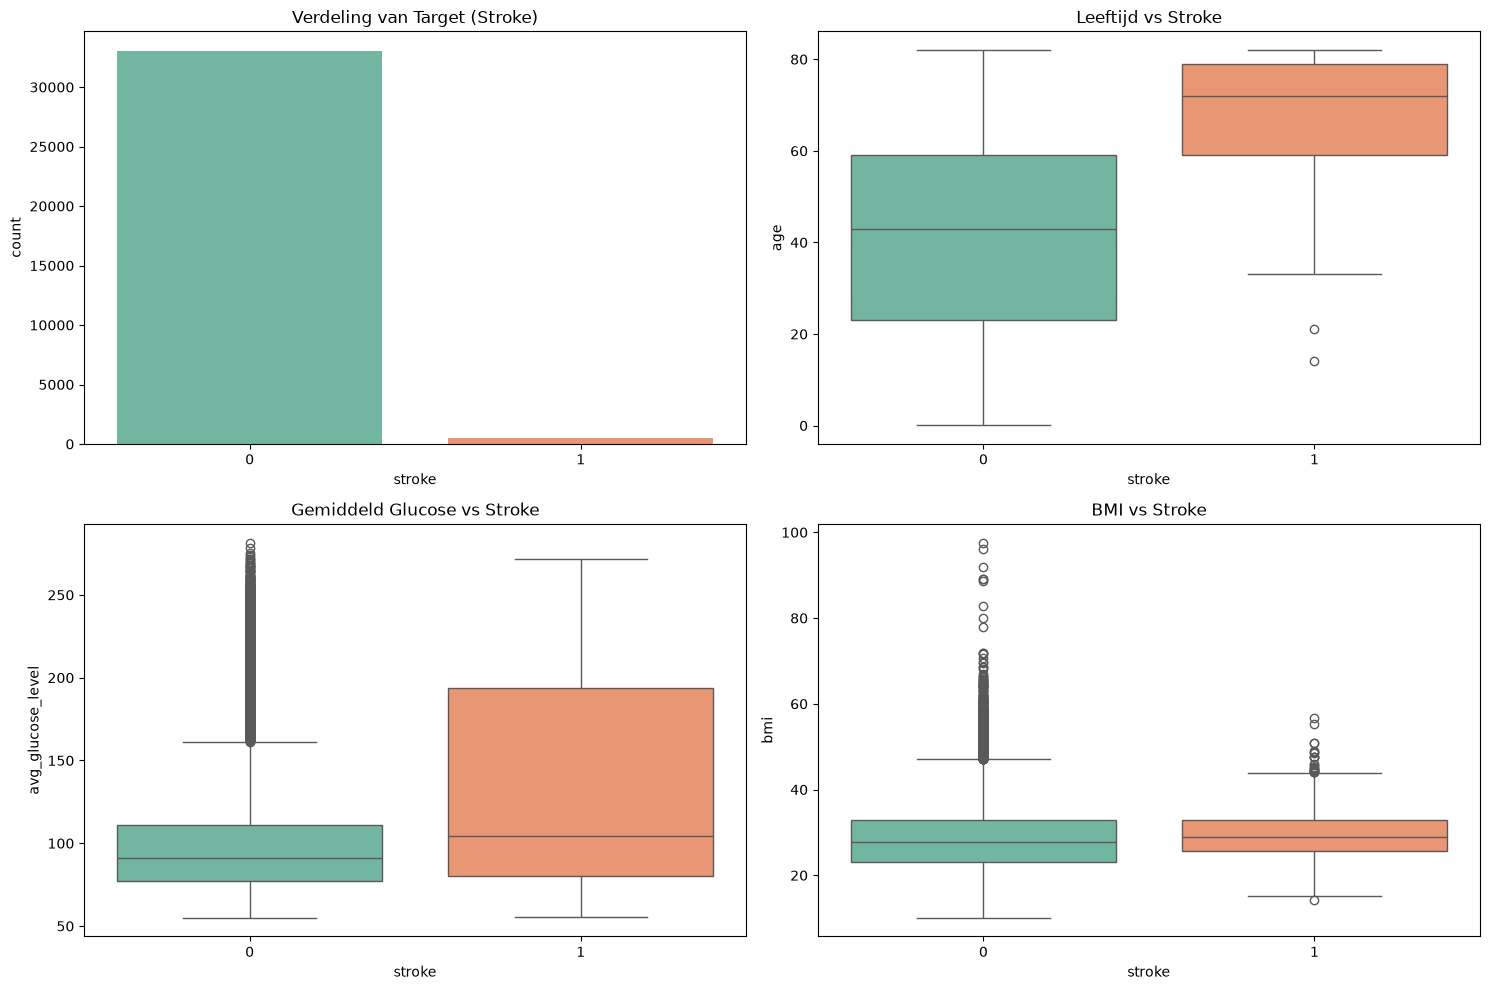

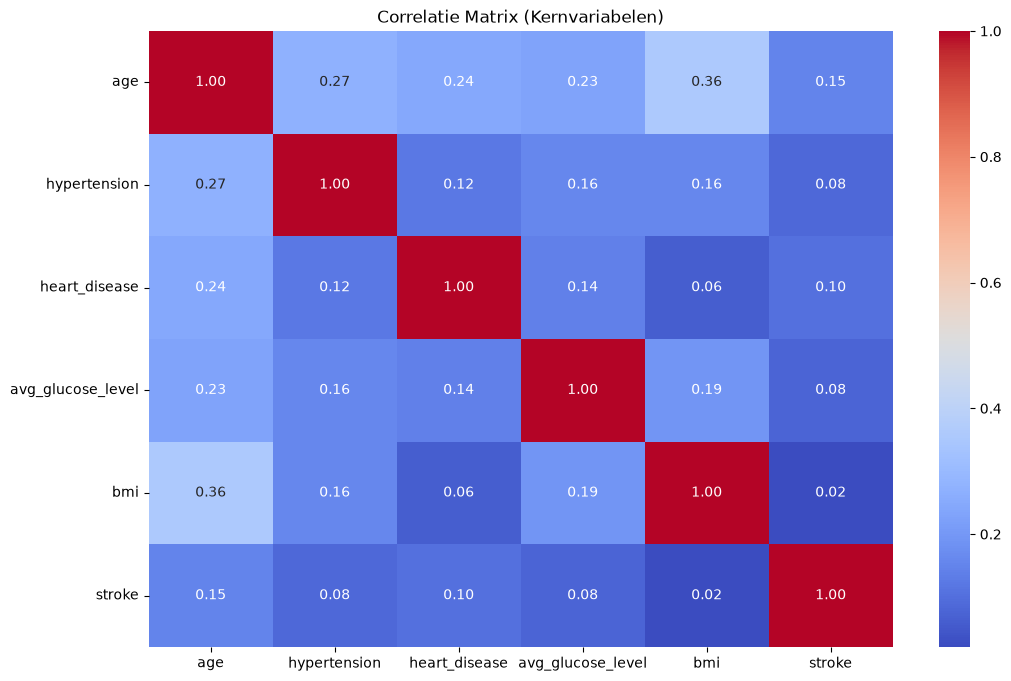

In [5]:
def plot_eda(df):
    """
    Maakt vier visualisaties die de belangrijkste eigenschappen van de data tonen:

    1. Verdeling van de target -> laat direct zien hoe sterk de klassen uit
       balans zijn. Dat is de aanleiding voor de imbalance-vergelijking verderop.
    2. Leeftijd vs stroke -> boxplot: is er een verschil in leeftijdsverdeling
       tussen de twee klassen?
    3. Glucose vs stroke -> zelfde vraag voor het glucosegehalte.
    4. BMI vs stroke -> zelfde vraag voor de BMI.

    Boxplots zijn hier geschikt omdat ze mediaan, spreiding en uitschieters in
    één oogopslag tonen, ook wanneer de klassen erg ongelijk verdeeld zijn.
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Sinds seaborn 0.14 is `palette` zonder `hue` gedeprecieerd. Door de
    # klasse óók als `hue` mee te geven (met legend=False) houden we exact
    # dezelfde kleuren per klasse, maar dan zonder FutureWarning.
    # 1. Verdeling van Stroke (Imbalanced check)
    sns.countplot(x='stroke', data=df, ax=axes[0, 0], hue='stroke',
                  palette='Set2', legend=False)
    axes[0, 0].set_title('Verdeling van Target (Stroke)')

    # 2. Leeftijd vs Stroke
    sns.boxplot(x='stroke', y='age', data=df, ax=axes[0, 1], hue='stroke',
                palette='Set2', legend=False)
    axes[0, 1].set_title('Leeftijd vs Stroke')

    # 3. Glucose vs Stroke
    sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[1, 0],
                hue='stroke', palette='Set2', legend=False)
    axes[1, 0].set_title('Gemiddeld Glucose vs Stroke')

    # 4. BMI vs Stroke
    sns.boxplot(x='stroke', y='bmi', data=df, ax=axes[1, 1], hue='stroke',
                palette='Set2', legend=False)
    axes[1, 1].set_title('BMI vs Stroke')

    plt.tight_layout()
    plt.show()


plot_eda(train_df)

# --- Correlatiematrix -------------------------------------------------------
# We selecteren alleen de numerieke kernvariabelen voor de correlatie heatmap.
# De dummyvariabelen laten we weg: die hebben een andere schaal en zouden het
# beeld vertroebelen.
# Let op de eenheden: de Pearson-correlatie is hier vooral bruikbaar als
# rangorde, niet als bewijs van causaliteit.
plt.figure(figsize=(12, 8))
num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(train_df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlatie Matrix (Kernvariabelen)')
plt.show()

### 2.5 Belangrijkste bevindingen van de EDA

1. **Zeer imbalanced dataset**: het overgrote deel van de patiënten heeft geen stroke (0). Slechts een klein percentage heeft wel een stroke (1). Dit bepaalt de hele modelaanpak: accuracy is een misleidende maatstaf en de classificatiedrempel moet getuned worden.
2. **Leeftijd**: patiënten met een stroke zijn gemiddeld significant ouder.
3. **Glucose & BMI**: er is een zichtbare correlatie; hogere glucosewaarden en extremere BMI-waarden komen vaker voor bij de stroke-groep.
4. **Hypertension & heart disease**: deze binaire variabelen tonen een positieve correlatie met de target.

Deze bevindingen verklaren waarom de latere modellen vooral `age`, `avg_glucose_level`,
`bmi`, `hypertension` en `heart_disease` gebruiken om te splitsen.

---

## 3. Data opschonen en voorbereiden

### 3.1 Irrelevante kolommen verwijderen

We verwijderen de `id`-kolom: dit is een identificatienummer zonder voorspellende waarde.
Omdat scikit-learn niet bij alle algoritmen goed met ontbrekende waarden omgaat, voegen we
daarnaast een imputatiestap toe in de modeling pipeline (zie §3.3).

De uitvoering staat bewust op één plek: de gedeelde functie `load_stroke_data` in §3.4,
zodat alle teamleden exact dezelfde opgeschoonde data en kolomvolgorde gebruiken.

### 3.2 Standaardisatie van de data

**Wat is het?** Standaardisatie zet kenmerken om naar ongeveer dezelfde schaal. Bij
`StandardScaler` wordt het gemiddelde 0 en de standaardafwijking 1. In eenvoudige vorm:

$$
z = \frac{x - \text{gemiddelde}}{\text{standaardafwijking}}
$$

**Wanneer is het belangrijk?** Vooral bij algoritmen die met afstanden werken, zoals KNN
en SVM, en bij Logistic Regression. Zonder schaling zou een kenmerk met grote getallen,
zoals `avg_glucose_level`, veel zwaarder meetellen dan een dummyvariabele met alleen 0 en 1.

**Voor deze dataset.** Voor boommodellen is standaardisatie niet noodzakelijk, omdat bomen
met grenswaarden werken. We gebruiken wel één vaste pipeline voor alle modellen. Daardoor
worden de gegevens op dezelfde manier voorbereid en staat de schaling op de juiste plek
binnen de cross-validation.

**Alle kolommen worden geschaald, ook de 0/1-dummy's.** Dat is niet foutloos: een
zeldzame categorie krijgt na standaardisatie een extreme waarde. `gender_Other` komt bij
6 van de 33.550 patiënten voor; zo'n patiënt krijgt $z \approx 75$ op die kolom (het
gemiddelde is bijna 0 en de standaardafwijking heel klein) en wordt in KNN en SVM als
uitschieter behandeld. Ongeschaald zou die bijdrage 0 of 1 zijn, net als bij de andere
dummy's.

**Waarom we dat toch zo laten.** We hebben de variant getest waarin alleen de continue
variabelen (`age`, `avg_glucose_level`, `bmi`) worden geschaald en de dummy's ongemoeid
blijven (via een `ColumnTransformer` met de rest ongewijzigd). Die variant gaf op de
cross-validation een iets hogere F1 (KNN met undersampling: 0,141 tegen 0,137), maar op de
onafhankelijke validatieset viel KNN juist sterk terug (0,081 tegen 0,133). De oorzaak zat
in de drempel: de OOF-optimale drempel verschoof van 0,32 naar 0,38 en die verschuiving
droeg niet over naar nieuwe data. Ook met een gladgestreken drempelcurve, de fold-mediaan
of het midden van het plateau bleef die verschuiving staan. De winst op de OOF-kansen valt
bovendien binnen de ruis, het risico op nieuwe data is groot, en de bestaande inzending
(KNN met undersampling) scoorde al 0,13256 op de leaderboard. Daarom houden we de
eenvoudige aanpak: alles schalen, één vaste pipeline voor alle modellen.

### 3.3 Imbalanced data

Onze dataset is imbalanced: slechts 517 van de 33.550 patiënten heeft `stroke = 1`
(ongeveer 1,54%). Daardoor kan een model snel een hoge accuracy halen door bijna altijd
'geen stroke' te voorspellen, terwijl het juist de positieve gevallen mist.

Daarom vergelijken we verschillende technieken:

1. **SMOTE** maakt extra, kunstmatige voorbeelden van de minderheidsklasse. Dit gebeurt
   binnen de pipeline en dus alleen op de trainingsfold. Zo voorkomen we dat informatie
   uit de validatiefold uitlekt.
2. **class_weight='balanced'** geeft fouten bij de minderheidsklasse meer gewicht. Het
   model wordt daardoor sterker afgestraft als het een stroke mist. Bij XGBoost gebruiken
   we hiervoor `scale_pos_weight`.
3. **Random undersampling** verkleint de meerderheidsklasse binnen elke CV-fold. Dit
   gebruiken we bij KNN, omdat KNN geen `class_weight` heeft.

SMOTE en class weights worden niet tegelijk toegepast, omdat de positieve klasse dan dubbel
wordt gecompenseerd. Per model vergelijken we de technieken met cross-validation en de
F1-score.

In [6]:
def maak_pipeline(model: object, use_smote: bool = True) -> object:
    """
    Bouwt één pipeline met alle voorbewerking plus het model.

    De volgorde van de stappen is bewust gekozen:

    1. `SimpleImputer(strategy='median')` - vult ontbrekende waarden met de
       mediaan. De mediaan is hier geschikter dan het gemiddelde, omdat
       `avg_glucose_level` en `bmi` scheef verdeeld zijn en gevoelig zijn voor
       uitschieters.
    2. `StandardScaler` - zet elke feature op gemiddelde 0 en standaardafwijking 1.
       Nodig voor KNN en SVM; voor de boommodellen onschadelijk. In §3.2 staat
       waarom we ook de 0/1-dummy's schalen.
    3. `SMOTE` (optioneel) - maakt synthetische voorbeelden van de
       minderheidsklasse aan.
    4. het model zelf.

    Belangrijk: alle stappen zitten in *één* pipeline die binnen elke
    cross-validation-fold opnieuw wordt gefit. Daardoor wordt SMOTE alleen op de
    trainingsfold toegepast en lekt er geen informatie uit de validatiefold. Zou
    je SMOTE vooraf op de hele dataset toepassen, dan scoort het model te
    optimistisch en zakt het op de leaderboard in.

    Met SMOTE is een `ImbPipeline` nodig (uit imblearn); zonder SMOTE volstaat de
    gewone sklearn `Pipeline`. Beide hebben dezelfde API, dus de rest van de code
    hoeft geen verschil te kennen.

    Parameters
    ----------
    model : sklearn classifier
        Het te gebruiken model.
    use_smote : bool
        Of SMOTE toegepast moet worden.

    Returns
    -------
    Pipeline
        De volledige pipeline.
    """
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]

    if use_smote:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
        return ImbPipeline(steps=steps + [('classifier', model)])
    return Pipeline(steps=steps + [('classifier', model)])

### 3.4 Voorbereiding van de dataset

Alle teamleden gebruiken dezelfde train/validatiesplit en dezelfde `random_state` (42).
De dataset bevat een `id`-kolom die niet voorspellend is en dus verwijderd wordt.

De split is *stratified*: de verhouding tussen `stroke = 0` en `stroke = 1` blijft gelijk
in de trainings- en de validatieset. Dat is noodzakelijk omdat er anders folds kunnen
ontstaan met extreem weinig positieve gevallen (of zelfs nul).

In [7]:
def load_stroke_data(train_path: str, test_path: str) -> tuple:
    """
    Laadt de stroke datasets en verwijdert irrelevante kolommen.

    Dit is de gedeelde laadfunctie voor het hele team: overal dezelfde
    conversie van booleans naar 0/1 en dezelfde kolomkeuzes, zodat alle
    modellen op exact dezelfde invoer trainen.

    Parameters
    ----------
    train_path : str
        Pad naar train.csv
    test_path : str
        Pad naar test.csv

    Returns
    -------
    tuple
        X_train, y_train, X_test, ids_test
    """
    train_df = converteer_bool_kolommen(pd.read_csv(train_path))
    test_df = converteer_bool_kolommen(pd.read_csv(test_path))

    # Verwijder de niet-voorspellende id-kolom; `stroke` is de doelvariabele en
    # hoort niet in X_train. De test-ids worden bewaard voor de submission.
    X_train = train_df.drop(columns=['id', 'stroke'])
    y_train = train_df['stroke']
    X_test = test_df.drop(columns=['id'])
    ids_test = test_df['id']

    return X_train, y_train, X_test, ids_test


# Laad de data
X_train, y_train, X_test, ids_test = load_stroke_data(
    'train.csv', 'test.csv'
)

# Maak dezelfde train/validation split als de andere teamleden.
# stratify=y_train: de klassenverhouding (ongeveer 1,54% positief) blijft in
# beide delen gelijk. Zonder stratificatie kan de validatieset toevallig bijna
# geen positieve gevallen bevatten, waardoor de F1-score onbruikbaar wordt.
# test_size=0.2: 20% van de data wordt gebruikt om het model onafhankelijk van
# de tuning te beoordelen. Deze set wordt tijdens de tuning nooit aangeraakt.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Trainingsgrootte: {X_tr.shape[0]}")
print(f"Validatiegrootte: {X_val.shape[0]}")
print(f"Targetverdeling training:\n{y_tr.value_counts()}")

Trainingsgrootte: 26840
Validatiegrootte: 6710
Targetverdeling training:
stroke
0    26426
1      414
Name: count, dtype: int64


## 4. Evaluatie

Een classificatiemodel beoordelen we met de **confusion matrix**: een tabel die de voorspellingen van het model kruist met de werkelijke uitkomsten.

| | Voorspeld: geen stroke | Voorspeld: stroke |
|---|---|---|
| **Werkelijk: geen stroke** | TN (true negative) | FP (false positive) |
| **Werkelijk: stroke** | FN (false negative) | TP (true positive) |

Uit deze vier getallen volgen alle gebruikte metrics:

$$
\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
\qquad
\text{precision}=\frac{TP}{TP+FP}
\qquad
\text{recall}=\frac{TP}{TP+FN}
$$

$$
F_1=2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}
=\frac{2\,TP}{2\,TP+FP+FN}
$$

* **Accuracy** meet welk deel van álle voorspellingen klopt.
* **Precision** meet welk deel van de voorspelde strokes er echt is (weinig vals alarm).
* **Recall** meet welk deel van de echte strokes het model vindt.
* **F1** is het harmonisch gemiddelde van precision en recall.

**Waarom F1 hier de beste maatstaf is.** Slechts 1,54% van de patiënten heeft een stroke. Een model dat *iedereen* 'geen stroke' voorspelt, haalt daarmee ruim 98% accuracy, maar herkent geen enkele patiënt — klinisch nutteloos. Accuracy is dus misleidend; precision en recall zijn beide belangrijk, maar schuiven tegen elkaar op (meer recall gaat vaak ten koste van precision). De F1-score weegt beide even zwaar en is precies de maatstaf van de Kaggle-competitie. Daarom tunen we de hyperparameters én de classificatiedrempel op F1.

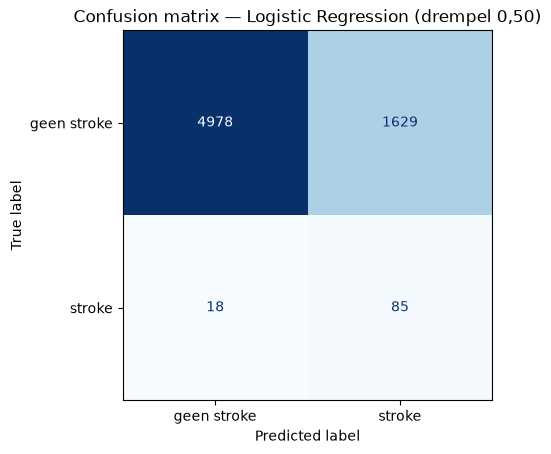

TP = 85,  FP = 1629,  FN = 18,  TN = 4978

accuracy  = (TP+TN)/(TP+TN+FP+FN) = 0.7545
precision = TP/(TP+FP)             = 0.0496
recall    = TP/(TP+FN)             = 0.8252
F1        = 2*TP/(2*TP+FP+FN)      = 0.0936


In [8]:
# Uitkomsten van een zelfgekozen algoritme (Logistic Regression) op de
# onafhankelijke validatieset, met de standaarddrempel 0,50. In de
# modeltraining (sectie 5) tunen we de drempel weg van 0,50; deze demo
# gebruikt bewust de standaarddrempel zodat de confusion matrix goed leesbaar is.
demo_model = maak_pipeline(
    LogisticRegression(solver='saga', max_iter=5000,
                       class_weight='balanced', random_state=RANDOM_STATE),
    use_smote=False,
)
demo_model.fit(X_tr, y_tr)
demo_pred = (demo_model.predict_proba(X_val)[:, 1] >= 0.5).astype(int)

# Confusion matrix: TP, FP, FN en TN in één oogopslag.
ConfusionMatrixDisplay.from_predictions(
    y_val, demo_pred, display_labels=['geen stroke', 'stroke'],
    cmap='Blues', colorbar=False)
plt.title('Confusion matrix — Logistic Regression (drempel 0,50)')
plt.show()

# De metrics, doorgerekend met de getallen uit de confusion matrix. Precision
# en recall zijn afgeschermd tegen een noemer van nul (dan is de metric 0),
# zodat deze cel ook blijft werken als een model geen enkele positieve
# voorspelling doet.
tn, fp, fn, tp = confusion_matrix(y_val, demo_pred).ravel()
print(f"TP = {tp},  FP = {fp},  FN = {fn},  TN = {tn}\n")

precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
print(f"accuracy  = (TP+TN)/(TP+TN+FP+FN) = {(tp + tn) / (tp + tn + fp + fn):.4f}")
print(f"precision = TP/(TP+FP)             = {precision:.4f}")
print(f"recall    = TP/(TP+FN)             = {recall:.4f}")
print(f"F1        = 2*TP/(2*TP+FP+FN)      = {2 * tp / (2 * tp + fp + fn):.4f}")

**Resultatentabel (vast format voor het hele team).** Alle resultaten komen in één tabel met vaste kolommen, zodat modellen onderling én met de Kaggle-leaderboard te vergelijken zijn:

| Kolom | Betekenis |
|---|---|
| `model` | naam van het model met de gekozen imbalance-variant |
| `notebook-score` | de validatie-F1 (val-F1) van de ingezonden variant — gemeten op data die niet voor de tuning is gebruikt; die score valt systematisch iets hoger uit dan de Kaggle-score |
| `Kaggle-score` | de F1-score op de Kaggle-leaderboard na het uploaden van de submission |

De tabel hieronder bevat de scores van de huidige inzendingen per model. Alleen
Ensemble 1 is opnieuw gegenereerd (zie §7) en moet opnieuw geüpload worden; in sectie 9
staat per model welke variant we inzenden en wat de conclusie is.

In [9]:
# Vast format van de resultatentabel: model | notebook-score | Kaggle-score.
# De scores komen uit de inzendrondes met de huidige voorbewerking (§3.2); de
# varianten per model staan in `INGEZONDEN_VARIANT` (§5).
#
# Let op: Ensemble 1 is opnieuw gegenereerd, omdat de componenten zijn
# gelijkgetrokken met de varianten die we per model inzenden (§7). Dat bestand
# moet opnieuw geüpload worden; vul de Kaggle-score daarna hier in.
#
# Het label moet exact overeenkomen met het label in de eindtabel van sectie 9,
# anders blijft die score daar leeg.
resultaten_tabel = pd.DataFrame(
    [
        ['K-Nearest Neighbors (undersampling)', 0.1325, 0.13256],
        ['Random Forest (class weights)', 0.1399, 0.10852],
        ['Ensemble 2: SVM + Random Forest + Logistic Regression', 0.1176, 0.10743],
        ['SVM (class weights)', 0.1290, 0.09523],
        ['Logistic Regression (geen techniek)', 0.1377, 0.09493],
        ['Decision Tree (smote)', 0.1043, 0.08962],
        ['Gradient Boosting (GBDT) (class weights)', 0.1011, 0.07228],
        ['XGBoost (geen techniek)', 0.1024, 0.07213],
        ['Ensemble 1: Random Forest + GBDT + XGBoost', 0.1182, np.nan],
    ],
    columns=['model', 'notebook-score', 'Kaggle-score'],
)

display(resultaten_tabel)

,model,notebook-score,Kaggle-score
0,K-Nearest Neighbors (undersampling),0.1325,0.13256
1,Random Forest (class weights),0.1399,0.10852
2,Ensemble 2: SVM + Random Forest + Logistic Reg...,0.1176,0.10743
3,SVM (class weights),0.1290,0.09523
4,Logistic Regression (geen techniek),0.1377,0.09493
5,Decision Tree (smote),0.1043,0.08962
6,Gradient Boosting (GBDT) (class weights),0.1011,0.07228
7,XGBoost (geen techniek),0.1024,0.07213
8,Ensemble 1: Random Forest + GBDT + XGBoost,0.1182,NaN


## 5. Modeltraining: vaste werkwijze voor alle modellen

We trainen en beoordelen alle modellen zoveel mogelijk op dezelfde manier. Dat hebben we
als groep afgesproken, zodat de scores eerlijk met elkaar te vergelijken zijn:

- **Datasplit:** dezelfde gestratificeerde train-validatiesplit, vijfvoudige cross-validation
en `random_state = 42`.
- **Hyperparameters:** `train_en_evalueer` gebruikt Optuna met een TPE-sampler. Optuna
  probeert niet blind ieder mogelijk raster af, maar gebruikt eerdere resultaten om nieuwe
  keuzes te maken. Daardoor is het bij onze zoekruimtes praktischer dan GridSearchCV.
- **Drempel:** we testen drempels van 0,01 tot 0,95. Bij een imbalanced dataset is 0,50
  namelijk vaak niet de beste drempel voor F1.
- **Metriek:** we gebruiken de F1-score voor `stroke = 1`, omdat dat ook de Kaggle-metriek is.
- **Keuze tussen de imbalance-varianten:** de varianten worden getuned en
  vergeleken op de CV-F1, dus over alle 26.840 trainingsrijen met 414 positieve
  gevallen. De validatieset heeft er maar 103 en is daardoor te klein om zo'n
  keuze op te baseren; die rapporteert alleen (de kolom `notebook-score`).
- **Welke variant we inzenden** staat expliciet in `INGEZONDEN_VARIANT` (zie de
  code hieronder). Die keuze komt uit de inzendrondes met de vorige
  voorbewerking (§9.2): per model is gekeken welke variant op de publieke
  leaderboard het beste scoorde. Let wel: die score wordt op ongeveer 49% van de
  testset berekend (circa 60 positieve gevallen), dus de verschillen tussen
  varianten zijn klein en ruizig. Zowel de ensembles (§7 en §8) als de
  inzendingen (§10) gebruiken deze ene keuze, zodat een model en zijn submission
  consistent blijven.

De CV-F1 is handig om modellen tijdens het trainen te vergelijken, maar is geen garantie
voor de Kaggle-score. Daarom kijken we ook naar de onafhankelijke validatieset. De functie
`vergelijk_imbalance_technieken` vergelijkt standaard geen techniek, SMOTE en class weights.
KNN gebruikt daarnaast undersampling, XGBoost stelt het klassegewicht zelf in en SVM heeft
voor sommige varianten een aangepaste zoekruimte. Deze uitzonderingen leggen we uit bij
het betreffende model.

In [10]:
class StopBijGeenVerbetering:
    """
    Optuna-callback die de studie stopt zodra er geen verbetering meer komt.

    Zo wordt er net zolang doorgezocht tot de hoogste F1-score is gevonden,
    zonder onnodig veel trials te verspillen.

    Werking: wordt de huidige trial de nieuwe beste, dan begint de teller opnieuw
    bij 0. Zoniet, dan loopt de teller op. Bij `patience` trials op rij zonder
    verbetering wordt de studie afgebroken. Dit is dus een *early stopping* op
    het zoekproces, niet op het model zelf.
    """

    def __init__(self, patience: int = 25) -> None:
        self.patience = patience
        self.teller = 0

    def __call__(self, study: optuna.Study,
                 trial: optuna.trial.FrozenTrial) -> None:
        if study.best_trial.number == trial.number:
            self.teller = 0          # nieuwe beste -> teller resetten
        else:
            self.teller += 1
        if self.teller >= self.patience:
            study.stop()


def train_en_evalueer(model: Any, param_grid: dict, naam: str,
                      use_smote: bool = True, n_trials: int = 150,
                      patience: int = 25, sampler: Any = None) -> dict:
    """
    Traint een model met Bayesiaanse optimalisatie en evalueert met
    een getunede classificatiedrempel.

    Optuna zoekt in de discrete zoekruimte van param_grid. Iedere trial wordt
    beoordeeld op de F1-score die met de beste classificatiedrempel binnen de
    cross-validation wordt behaald. Dat is precies de maatstaf die ook voor de
    eindscore gebruikt wordt, zodat de zoektocht echt de hoogste F1-score
    oplevert. Er worden net zolang nieuwe combinaties geprobeerd totdat
    `patience` trials op rij geen hogere F1-score meer opleveren, of tot
    `n_trials` is bereikt. De validatieset blijft onafhankelijk van de
    hyperparameterkeuze en drempelkeuze.

    Standaard zoekt de TPE-sampler van Optuna de combinaties. Voor een heel
    kleine, uitputtend doorzoekbare zoekruimte (zoals de zeven stemgewichten
    van een ensemble) kan via `sampler` een `GridSampler` worden meegegeven;
    dan komt elke combinatie precies één keer aan bod.
    """
    # Eén pipeline per aanroep. Elke trial is een kloon met andere parameters,
    # zodat de originele pipeline niet vervuild raakt.
    pipeline: Any = maak_pipeline(model, use_smote)

    # Vijfvoudige stratified CV: elke fold houdt dezelfde klassenverhouding,
    # essentieel bij slechts ~1,5% positieve gevallen.
    cv = StratifiedKFold(n_splits=5, shuffle=True,
                         random_state=RANDOM_STATE)

    # De drempelreeks begint laag: bij deze sterk imbalanced data ligt het
    # optimum vaak onder 0,10 en mag de ondergrens de zoektocht niet afkappen.
    drempels = np.arange(0.01, 0.96, 0.01)

    # Sommige zoekruimtes bevatten samengestelde waarden (een lijst als waarde).
    # Optuna kan dat niet rechtstreeks voorstellen; zulke parameters worden
    # hieronder als index aangeboden en daarna terugvertaald.
    compound_parameters = {
        parameter: values
        for parameter, values in param_grid.items()
        if values and isinstance(values[0], (list, tuple))
    }

    def beste_f1_bij_drempel(probabilities: np.ndarray) -> tuple:
        """Geeft de hoogste F1-score en de bijbehorende drempel."""
        scores = {
            threshold: f1_score(
                y_tr,
                (probabilities >= threshold).astype(int)
            )
            for threshold in drempels
        }
        beste_drempel = max(scores, key=lambda drempel: scores[drempel])
        return scores[beste_drempel], beste_drempel

    def objective(trial: optuna.Trial) -> float:
        """Optuna-doelfunctie: bouw de pipeline en geef de OOF-F1 terug."""
        trial_params = {}
        for parameter, values in param_grid.items():
            if parameter in compound_parameters:
                choice_index = trial.suggest_int(
                    f'{parameter}__choice',
                    0,
                    len(values) - 1
                )
                trial_params[parameter] = values[choice_index]
            else:
                trial_params[parameter] = trial.suggest_categorical(
                    parameter,
                    values
                )

        trial_pipeline = clone(pipeline).set_params(**trial_params)

        # cross_val_predict geeft *out-of-fold* kansen: elke voorspelling komt
        # van een model dat die rij niet gezien heeft. Zo kan de drempel getuned
        # worden zonder de validatieset te gebruiken.
        oof_probabilities = cross_val_predict(
            trial_pipeline,
            X_tr,
            y_tr,
            cv=cv,
            method='predict_proba',
            n_jobs=-1
        )[:, 1]
        # Maximaliseer de F1-score met de beste drempel binnen deze CV.
        beste_f1, _ = beste_f1_bij_drempel(oof_probabilities)
        return beste_f1

    study = optuna.create_study(
        direction='maximize',
        sampler=sampler or optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )
    study.optimize(
        objective,
        n_trials=n_trials,
        callbacks=[StopBijGeenVerbetering(patience)],
        show_progress_bar=False
    )

    # Zet de beste trial-indexen weer om naar echte parameterwaarden.
    best_params = {}
    for parameter, values in param_grid.items():
        if parameter in compound_parameters:
            choice_index = study.best_params[f'{parameter}__choice']
            best_params[parameter] = values[choice_index]
        else:
            best_params[parameter] = study.best_params[parameter]

    best_model = clone(pipeline).set_params(**best_params)
    best_model.fit(X_tr, y_tr)

    # Bepaal de definitieve drempel met out-of-fold kansen van het beste model.
    # n_jobs=-1, gelijk aan de zoekfase: XGBoost bouwt histogrammen met
    # meerdere threads niet volledig deterministisch, dus een ander aantal
    # threads zou hier een andere (en lagere) CV-score opleveren dan de
    # zoektocht zelf vond.
    oof_probabilities = cross_val_predict(
        best_model,
        X_tr,
        y_tr,
        cv=cv,
        method='predict_proba',
        n_jobs=-1
    )[:, 1]
    threshold_aware_cv_f1, best_threshold = beste_f1_bij_drempel(
        oof_probabilities
    )

    # Gebruik de gekozen drempel alleen voor de onafhankelijke validatieset.
    validation_probabilities = best_model.predict_proba(X_val)[:, 1]
    y_pred = (validation_probabilities >= best_threshold).astype(int)
    f1 = f1_score(y_val, y_pred)

    print(f"\n=== {naam} ===")
    print(f"Aantal uitgevoerde trials: {len(study.trials)}")
    print(f"Beste hyperparameters: {best_params}")
    print(f"Beste CV F1 tijdens zoeken (getunede drempel): "
          f"{study.best_value:.4f}")
    print(f"CV F1 beste model (getunede drempel): "
          f"{threshold_aware_cv_f1:.4f}")
    print(f"Gekozen classificatiedrempel: {best_threshold:.2f}")
    print(f"Validatie F1-score: {f1:.4f}")
    print(classification_report(y_val, y_pred))

    # Alles wat de aanroeper nodig heeft voor modelvergelijking en submissions.
    # `val_f1` is de score op data die nooit voor tuning is gebruikt en is
    # daardoor de beste voorspeller van de Kaggle-score.
    return {
        'naam': naam,
        'beste_params': best_params,
        'cv_f1': threshold_aware_cv_f1,
        'tuning_cv_f1': study.best_value,
        'val_f1': f1,
        'threshold': best_threshold,
        'n_trials': len(study.trials),
        'beste_model': best_model,
        'study': study
    }

In [11]:
def kies_beste_variant(resultaten: list) -> dict:
    """Geef de variant met de hoogste CV-F1 uit een lijst variant-resultaten.

    We kiezen bewust op CV-F1 en niet op val-F1. De cross-validation gebruikt
    alle 26.840 trainingsrijen met 414 positieve gevallen; de validatieset
    heeft er maar 103. Het maximum van een paar ruizige val-F1-scores kiest te
    vaak een variant die toevallig goed uitvalt op die 103 gevallen, terwijl de
    CV-F1 over vijf folds middelt en daardoor een betrouwbaarder
    selectiecriterium is (zie §5). Zo blijft de validatieset volledig buiten de
    modelkeuze en meet die alleen nog hoe de gekozen variant op nieuwe data
    presteert.
    """
    return max(resultaten, key=lambda variant: variant['cv_f1'])


# ---------------------------------------------------------------------------
# Welke variant zenden we per model in?
# ---------------------------------------------------------------------------
# Eén bron van waarheid voor de inzendingen: per model de variant die in de
# inzendrondes het beste presteerde op de publieke leaderboard (zie §9.2).
# Sectie 7 (eerste ensemble), sectie 9 (eindtabel) en sectie 10 (submissions)
# gebruiken allemaal deze keuze.
INGEZONDEN_VARIANT = {
    'K-Nearest Neighbors': 'Alleen undersampling',
    'Logistic Regression': 'Geen techniek',
    'SVM': 'Alleen class weights',
    'Decision Tree': 'Alleen SMOTE',
    'Random Forest': 'Alleen class weights',
    'Gradient Boosting (GBDT)': 'Alleen class weights',
    'XGBoost': 'Geen techniek (gewicht getuned)',
}


def kies_ingezonden_variant(model_naam: str, resultaat: dict) -> dict:
    """Geef het variant-resultaat dat we voor dit model inzenden.

    De keuze staat in `INGEZONDEN_VARIANT`, zodat er één plek is waar bepaald
    wordt wat er in de submission terechtkomt en sectie 7, 9 en 10 dezelfde
    variant gebruiken. `kies_beste_variant` (CV-F1) blijft de manier om
    varianten tijdens het tunen te vergelijken.
    """
    techniek = INGEZONDEN_VARIANT[model_naam]
    for variant in resultaat['alle_techniek_resultaten']:
        if variant['imbalance_techniek'] == techniek:
            return variant
    beschikbaar = [v['imbalance_techniek']
                   for v in resultaat['alle_techniek_resultaten']]
    raise KeyError(f"Variant '{techniek}' bestaat niet voor {model_naam}; "
                   f"kies uit {beschikbaar}")


def vergelijk_imbalance_technieken(model_factory: object,
                                   param_grid: dict,
                                   naam: str,
                                   n_trials: int = 150,
                                   patience: int = 25,
                                   varianten: list | None = None) -> dict:
    """
    Vergelijkt imbalance-varianten en houdt de beste over.

    Standaard worden geen techniek, alleen SMOTE en alleen class weights
    vergeleken. Via `varianten` kan een model daarvan afwijken, bijvoorbeeld
    wanneer het klassegewicht zelf al een tunbare hyperparameter is en de
    variant 'class weights' daardoor samenvalt met 'geen techniek'.

    Een variant is een tuple (naam, use_smote, use_weights) en mag optioneel
    een eigen `param_grid` als vierde element meekrijgen. Dat is nodig wanneer
    een hyperparametercombinatie aantoonbaar niet convergeert; die combinatie
    wordt dan per variant uit de zoekruimte gehouden in plaats van de
    bijbehorende waarschuwing te onderdrukken (zie §6.3).

    `model_factory` krijgt één argument (`use_weights`) en levert een *vers*
    model zonder hyperparameters; die worden immers per trial door Optuna
    gekozen. Zo kan dezelfde functie alle varianten opbouwen.
    """
    if varianten is None:
        varianten = [
            ('Geen techniek', False, False),
            ('Alleen SMOTE', True, False),
            ('Alleen class weights', False, True),
        ]
    resultaten = []

    # Elke variant wordt volledig opnieuw getuned: de beste hyperparameters
    # kunnen immers per imbalance-techniek verschillen.
    for variant in varianten:
        variant_naam, use_smote, use_weights = variant[:3]
        variant_param_grid = variant[3] if len(variant) > 3 else param_grid
        resultaat = train_en_evalueer(
            model=model_factory(use_weights),
            param_grid=variant_param_grid,
            naam=f'{naam} - {variant_naam}',
            use_smote=use_smote,
            n_trials=n_trials,
            patience=patience
        )
        resultaat['imbalance_techniek'] = variant_naam
        resultaten.append(resultaat)

    # De varianten worden vergeleken op CV-F1; zie `kies_beste_variant` voor
    # de onderbouwing van dat criterium.
    beste_resultaat = kies_beste_variant(resultaten)
    print(
        f"Beste imbalance-techniek voor {naam} (op CV-F1): "
        f"{beste_resultaat['imbalance_techniek']} "
        f"(CV F1: {beste_resultaat['cv_f1']:.4f})"
    )

    # Alle varianten worden bewaard, zodat de scores later bij de
    # modelvergelijking (en in de resultatentabel) gebruikt kunnen worden —
    # inclusief de val_f1 per variant.
    beste_resultaat['alle_techniek_resultaten'] = resultaten
    return beste_resultaat

## 6. Modellen

In deze sectie behandelen we de modellen die bij de taakverdeling horen. We beginnen met
KNN en Logistic Regression van Persoon A. Daarna volgen SVM en Decision Tree van Persoon B.
Tot slot bespreken en testen we Random Forest, GBDT en XGBoost van Persoon C.

De modellen worden met dezelfde pipeline en dezelfde evaluatiefunctie getraind. Daardoor
kunnen we de invloed van het model en de gekozen imbalance-techniek beter vergelijken.
In sectie 7 en 8 bouwen we twee VotingClassifier-ensembles.

### 6.1 K-Nearest Neighbors (KNN)

KNN is een *lazy learner*: het model bewaart de trainingsdata en voorspelt voor een nieuwe patiënt de kans op stroke als het aandeel van de $k$ meest vergelijkbare (dichtstbijzijnde) trainingspatiënten:

$$
\hat{P}(y=1\mid x)=\frac{1}{k}\sum_{i\in N_k(x)}y_i
$$

**Afstand.** Of twee patiënten "dichtbij" zijn, bepalen we met de **Euclidean** ($p=2$) of **Manhattan** ($p=1$) afstand:

$$
d(x,z)=\sqrt{\sum_{j=1}^{m}(x_j-z_j)^2}
\qquad\text{of}\qquad
d(x,z)=\sum_{j=1}^{m}|x_j-z_j|
$$

**Standaardisatie is voor KNN cruciaal.** Elk kenmerk telt direct mee in de afstand, dus zonder schaling domineert `avg_glucose_level` (bereik ongeveer 55–282) volledig ten opzichte van `hypertension` (0/1) of één levensjaar verschil. Daarom loopt KNN in onze pipeline door `StandardScaler` (zie §3.2); de keuze tussen Manhattan en Euclidean tunen we met de parameter `p`.

**Regularisatie zit bij KNN in de hyperparameters**, niet in een strafterm: kleine $k$ (bijv. 1) is gevoelig voor uitschieters → hoge variantie en overfitting; grote $k$ middelt meer en is stabieler, maar kan patronen missen (underfitting). Ook `weights='distance'` (nabije buren zwaarder laten wegen) is een vorm van bijsturing.

KNN kent geen `class_weight`. Daarom vergelijken we naast "geen techniek" en SMOTE ook **random undersampling** van de meerderheidsklasse, uitgevoerd binnen iedere CV-fold (geen datalek). Welke hyperparameters het beste scoren op de gekozen metric (F1) volgt uit de tuning hieronder.

In [12]:
# ---------------------------------------------------------------------------
# KNN: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# - n_neighbors : aantal buren k; klein = gevoelig voor uitschieters
#                 (overfitting), groot = sterker regulariseren (onderfitting).
# - weights     : 'uniform' (elke buur even zwaar) of 'distance' (1/afstand).
# - p           : 1 = Manhattan, 2 = Euclidean.
knn_params = {
    'classifier__n_neighbors': [5, 15, 31, 51, 75, 101, 151, 201],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__p': [1, 2],
}

# KNN heeft geen class_weight: alleen 'geen techniek' en SMOTE via de template.
knn_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: KNeighborsClassifier(),
    param_grid=knn_params,
    naam='KNN',
    n_trials=150,
    patience=40,
    varianten=[
        ('Geen techniek', False, False),
        ('Alleen SMOTE', True, False),
    ],
)

# De derde variant is random undersampling. De undersampler zit ín de
# classifier-stap, zodat de balans per CV-fold opnieuw wordt aangelegd.
knn_under_params = {
    'classifier__undersampler__sampling_strategy': [0.1, 0.15, 0.25, 0.4, 0.5, 0.75, 1.0],
    'classifier__knn__n_neighbors': [5, 15, 31, 51, 75, 101],
    'classifier__knn__weights': ['uniform', 'distance'],
    'classifier__knn__p': [1, 2],
}
# Let op: de schaling gebeurt in de buitenste pipeline van `maak_pipeline`;
# die staat vóór deze classifier, dus de undersampler en KNN krijgen al
# geschaalde data.
knn_under_model = ImbPipeline([
    ('undersampler', RandomUnderSampler(random_state=RANDOM_STATE)),
    ('knn', KNeighborsClassifier()),
])
knn_under_resultaat = train_en_evalueer(
    knn_under_model,
    knn_under_params,
    'KNN - Alleen undersampling',
    use_smote=False,
    n_trials=150,
    patience=40,
)
knn_under_resultaat['imbalance_techniek'] = 'Alleen undersampling'

# Alle drie de varianten op één plek, voor de modelvergelijking, en
# herselecteer de winnaar nu de undersampling-variant is toegevoegd: zonder die
# herselectie blijft `knn_resultaten` de winnaar van de eerste twee varianten.
knn_varianten = knn_resultaten['alle_techniek_resultaten'] + [knn_under_resultaat]
knn_resultaten = kies_beste_variant(knn_varianten)
knn_resultaten['alle_techniek_resultaten'] = knn_varianten

# De print in `vergelijk_imbalance_technieken` ging alleen over de eerste twee
# varianten; hier volgt de winnaar van alle drie, zodat de uitvoer niet de
# indruk wekt dat 'geen techniek' de beste KNN-variant is.
print(f"Beste imbalance-techniek voor KNN inclusief de undersampling-variant: "
      f"{knn_resultaten['imbalance_techniek']} "
      f"(CV F1: {knn_resultaten['cv_f1']:.4f})")

[I 2026-10-06 23:35:31,022] A new study created in memory with name: no-name-addb4844-d553-4917-a5a6-caf9276fe6ce


[I 2026-10-06 23:35:32,860] Trial 0 finished with value: 0.09472422062350119 and parameters: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance', 'classifier__p': 2}. Best is trial 0 with value: 0.09472422062350119.


[I 2026-10-06 23:35:34,321] Trial 1 finished with value: 0.07772254857659286 and parameters: {'classifier__n_neighbors': 5, 'classifier__weights': 'uniform', 'classifier__p': 2}. Best is trial 0 with value: 0.09472422062350119.


[I 2026-10-06 23:35:37,218] Trial 2 finished with value: 0.09753231492361927 and parameters: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance', 'classifier__p': 1}. Best is trial 2 with value: 0.09753231492361927.


[I 2026-10-06 23:35:39,329] Trial 3 finished with value: 0.11097099621689786 and parameters: {'classifier__n_neighbors': 201, 'classifier__weights': 'distance', 'classifier__p': 2}. Best is trial 3 with value: 0.11097099621689786.


...

[I 2026-10-06 23:41:48,272] Trial 79 finished with value: 0.13114754098360656 and parameters: {'classifier__undersampler__sampling_strategy': 0.4, 'classifier__knn__n_neighbors': 51, 'classifier__knn__weights': 'uniform', 'classifier__knn__p': 1}. Best is trial 42 with value: 0.1366520253782333.


[I 2026-10-06 23:41:48,646] Trial 80 finished with value: 0.1233644859813084 and parameters: {'classifier__undersampler__sampling_strategy': 0.75, 'classifier__knn__n_neighbors': 101, 'classifier__knn__weights': 'uniform', 'classifier__knn__p': 2}. Best is trial 42 with value: 0.1366520253782333.


[I 2026-10-06 23:41:49,143] Trial 81 finished with value: 0.1366520253782333 and parameters: {'classifier__undersampler__sampling_strategy': 0.25, 'classifier__knn__n_neighbors': 101, 'classifier__knn__weights': 'uniform', 'classifier__knn__p': 1}. Best is trial 42 with value: 0.1366520253782333.


[I 2026-10-06 23:41:49,631] Trial 82 finished with value: 0.1366520253782333 and parameters: {'classifier__undersampler__sampling_strategy': 0.25, 'classifier__knn__n_neighbors': 101, 'classifier__knn__weights': 'uniform', 'classifier__knn__p': 1}. Best is trial 42 with value: 0.1366520253782333.



=== KNN - Alleen undersampling ===
Aantal uitgevoerde trials: 83
Beste hyperparameters: {'classifier__undersampler__sampling_strategy': 0.25, 'classifier__knn__n_neighbors': 101, 'classifier__knn__weights': 'uniform', 'classifier__knn__p': 1}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1367
CV F1 beste model (getunede drempel): 0.1367
Gekozen classificatiedrempel: 0.32
Validatie F1-score: 0.1325
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      6607
           1       0.08      0.39      0.13       103

    accuracy                           0.92      6710
   macro avg       0.53      0.66      0.55      6710
weighted avg       0.98      0.92      0.95      6710

Beste imbalance-techniek voor KNN inclusief de undersampling-variant: Alleen undersampling (CV F1: 0.1367)


### 6.2 Logistic Regression

Logistic Regression voorspelt eerst een lineaire combinatie van de kenmerken en zet die om in een kans met de sigmoid-functie:

$$
z=\beta_0+\beta_1x_1+\dots+\beta_mx_m,
\qquad
\hat{p}=P(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}
$$

In gewone taal: de sigmoid $\sigma$ perst de lineaire score $z$ samen tot een kans tussen 0 en 1. De log-odds zijn lineair in de kenmerken: $\ln(\hat{p}/(1-\hat{p}))=\beta_0+\boldsymbol{\beta}^T\mathbf{x}$. Daarom is $e^{\beta_j}$ de **odds ratio** per eenheid (bij onze gestandaardiseerde kenmerken: per standaardafwijking) en is het model een *lineaire classifier*.

**Loss-functie.** De coëfficiënten worden geschat door de gemiddelde *binary cross-entropy* (log loss) te minimaliseren; deze is convex, dus er is één globaal minimum:

$$
J(\beta)=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\ln(\hat{p}_i)+(1-y_i)\ln(1-\hat{p}_i)\right]
$$

Kort gezegd: voorspellingen die met grote zekerheid de verkeerde klasse kiezen, tellen zwaar mee in de straf — het model zoekt de coëfficiënten die deze totale straf minimaliseren.

**Gradient descent.** Het minimum wordt stap voor stap benaderd. De update-regel is eenvoudig: pas elke coëfficiënt aan in de richting tegengesteld aan de helling van de loss, met leersnelheid $\eta$:

$$
\beta_j := \beta_j-\eta\frac{\partial J}{\partial\beta_j}
$$

De helling $\frac{\partial J}{\partial\beta_j}$ is in deze context de gemiddelde voorspelfout maal kenmerk $x_j$: voorspelt het model structureel te hoge kansen, dan gaan de coëfficiënten omlaag — de updates bewegen dus automatisch de goede kant op.

Rekenvoorbeeld (drie patiënten, $\eta=0{,}5$, start $\beta_0=\beta_1=0$): na één update is $\beta_0=-0{,}0833$ en $\beta_1=0{,}25$, en daalt de loss van 0,6931 naar 0,5663 — de voorspelfout $\hat{p}_i-y_i$ stuurt de updates dus in de juiste richting.

**Regularisatie.** Een strafterm begrenst de coëfficiënten. De twee hoofdvormen zijn:

$$
J_{L2}=J+\lambda\sum_j\beta_j^2
\qquad\text{en}\qquad
J_{L1}=J+\lambda\sum_j|\beta_j|
$$

L2 krimpt alle coëfficiënten (stabiel bij de gecorreleerde dummy's), L1 zet zwakke coëfficiënten exact op 0 (ingebouwde feature selectie). Elastic Net is simpelweg een mengvorm van beide (via mengparameter $\alpha$). In scikit-learn regel je dit met $C=1/\lambda$ en `l1_ratio` (0 = L2, 0,5 = Elastic Net, 1 = L1); de solver `saga` ondersteunt alle drie.

**Regularisatie en overfitting.** Zonder strafterm kunnen de coëfficiënten onbeperkt groeien — zeker bij sterk gecorreleerde kenmerken of (bijna) perfect scheidbare data — en wordt het model té zeker van zichzelf: dat is overfitting. Regularisatie begrenst de coëfficiënten (iets meer bias, veel minder variantie) en bestrijdt daarmee overfitting; te sterke regularisatie (zeer kleine $C$) duwt de coëfficiënten juist naar 0 en geeft underfitting. De optimale sterkte kiezen we daarom met cross-validation.

Daarnaast vergelijken we de imbalance-varianten uit §3.3, waaronder `class_weight='balanced'`. Welke hyperparameters ($C$, `l1_ratio`) het beste scoren op de gekozen metric (F1) volgt uit de tuning hieronder.

In [13]:
# ---------------------------------------------------------------------------
# Logistic Regression: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# - C        : inverse regularisatiesterkte (C = 1/lambda). Klein = sterk
#              regulariseren, groot = zwak regulariseren.
# - l1_ratio : 0 = L2 (ridge), 0.5 = Elastic Net, 1 = L1 (lasso).
#              (Sinds scikit-learn 1.8 stuurt `l1_ratio` de strafterm direct;
#              de oudere parameter `penalty` is gedeprecieerd.)
#              Een fijnere C-reeks is getest: hogere CV-F1, maar lagere val-F1
#              (selectie-overfitting) — daarom bewust dit grove raster.
logreg_params = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0],
    'classifier__l1_ratio': [0.0, 0.5, 1.0],
}

# `saga` ondersteunt L2, L1 én Elastic Net; class_weight='balanced' hoort bij
# de derde imbalance-variant die de template aanstuurt.
logreg_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: LogisticRegression(
        solver='saga',
        max_iter=5000,
        class_weight='balanced' if use_weights else None,
        random_state=RANDOM_STATE,
    ),
    param_grid=logreg_params,
    naam='Logistic Regression',
    n_trials=60,
    patience=15,
)

[I 2026-10-06 23:41:50,211] A new study created in memory with name: no-name-f652514f-2662-4fdc-86b7-3d589d876fb2


[I 2026-10-06 23:41:51,666] Trial 0 finished with value: 0.1522086216072379 and parameters: {'classifier__C': 0.01, 'classifier__l1_ratio': 1.0}. Best is trial 0 with value: 0.1522086216072379.


[I 2026-10-06 23:41:54,644] Trial 1 finished with value: 0.1504539559014267 and parameters: {'classifier__C': 1.0, 'classifier__l1_ratio': 0.0}. Best is trial 0 with value: 0.1522086216072379.


[I 2026-10-06 23:41:58,405] Trial 2 finished with value: 0.15040825096691018 and parameters: {'classifier__C': 10.0, 'classifier__l1_ratio': 1.0}. Best is trial 0 with value: 0.1522086216072379.


[I 2026-10-06 23:41:59,710] Trial 3 finished with value: 0.1520912547528517 and parameters: {'classifier__C': 0.01, 'classifier__l1_ratio': 0.5}. Best is trial 0 with value: 0.1522086216072379.


...

[I 2026-10-06 23:44:23,174] Trial 13 finished with value: 0.15226939970717424 and parameters: {'classifier__C': 10.0, 'classifier__l1_ratio': 0.0}. Best is trial 1 with value: 0.15249266862170088.


[I 2026-10-06 23:44:24,547] Trial 14 finished with value: 0.15187376725838264 and parameters: {'classifier__C': 0.1, 'classifier__l1_ratio': 0.0}. Best is trial 1 with value: 0.15249266862170088.


[I 2026-10-06 23:44:28,647] Trial 15 finished with value: 0.15151515151515152 and parameters: {'classifier__C': 1.0, 'classifier__l1_ratio': 0.5}. Best is trial 1 with value: 0.15249266862170088.


[I 2026-10-06 23:44:29,237] Trial 16 finished with value: 0.1477832512315271 and parameters: {'classifier__C': 0.01, 'classifier__l1_ratio': 0.0}. Best is trial 1 with value: 0.15249266862170088.



=== Logistic Regression - Alleen class weights ===
Aantal uitgevoerde trials: 17
Beste hyperparameters: {'classifier__C': 1.0, 'classifier__l1_ratio': 0.0}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1525
CV F1 beste model (getunede drempel): 0.1525
Gekozen classificatiedrempel: 0.82
Validatie F1-score: 0.1258
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.08      0.30      0.13       103

    accuracy                           0.94      6710
   macro avg       0.53      0.62      0.55      6710
weighted avg       0.97      0.94      0.95      6710

Beste imbalance-techniek voor Logistic Regression (op CV-F1): Alleen SMOTE (CV F1: 0.1572)


### 6.3 SVM (Support Vector Machines)

Hieronder volgt eerst de theorie, daarna de implementatie met de gedeelde pipeline
en `train_en_evalueer`.

**Wat is het?** SVM is een supervised machine learning algoritme dat voornamelijk wordt gebruikt voor classificatie en soms ook voor regressietaken.

**Hoe werkt het?** SVM werkt door de beste beslissingsgrens of het beste hypervlak te vinden om datapunten in verschillende klassen te scheiden, en verschuift dit hypervlak ten opzichte van specifieke datapunten (supportvectoren) om het te optimaliseren. 

**Hoe het wiskundig werkt (met rekenvoorbeeld).** Het model zoekt een scheidingsvlak $w \cdot x + b = 0$ met twee eigenschappen: elk trainingspunt ligt aan de goede kant van het vlak ($y_i(w \cdot x_i + b) \ge 1$) en de marge — de lege strook tussen de twee klassen — is zo breed mogelijk. Die marge is $2/\|w\|$, dus het model maakt $\|w\|$ zo klein mogelijk. Rekenvoorbeeld met twee patiënten en één kenmerk (bijv. leeftijd op gestandaardiseerde schaal): patiënt A heeft $x=+1$ (stroke), patiënt B heeft $x=-1$ (geen stroke). Voor de supportvectoren geldt gelijkheid: $w \cdot 1 + b = 1$ en $w \cdot (-1) + b = -1$, dus volgt $w=1$ en $b=0$. De marge is dan $2/|w|=2$ en het beslissingsvlak ligt op $x=0$: links voorspelt het model 'geen stroke', rechts 'stroke'.

**Wat is een kernel?** Een kernel is een gelijkenisfunctie die berekent hoe dicht twee datapunten bij elkaar liggen. 

**Wat is de kernel trick?** De kernel trick is de truc om datapunten eerst wiskundig te transformeren (bijvoorbeeld door ze te kwadrateren), zodat ze van niet-lineair scheidbaar naar lineair scheidbaar worden — zónder die transformatie ook echt uit te rekenen. De kernelfunctie rekent namelijk direct het inwendig product van twee getransformeerde punten uit. Voor ons lineaire model is dat simpelweg het gewone inwendig product: $K(x_i, x_j) = x_i \cdot x_j$.

**Wat is de loss-functie en hoe werkt het?** De fout van het model meten we met de hinge loss: een punt dat correct én buiten de marge ligt, kost niets; alle andere punten kosten hun afstand tot de marge:

$$
L_i = \max(0,\ 1 - y_i(w \cdot x_i + b))
$$

Het model zoekt dus de gewichten die de marge maximaliseren én de totale fout zo klein mogelijk houden; de afweging daartussen wordt gestuurd door $C$.

**Welke vormen van regularisatie zijn hier van toepassing en hoe werkt ze?** Lineaire SVM's gebruiken **L2-regularisatie**: de strafterm $\frac{1}{2}\|w\|^2$ houdt de gewichtsvector klein, wat de oplossing glad en stabiel maakt en overfitting tegengaat. De hyperparameter $C$ weegt de twee doelen tegen elkaar af: een kleine $C$ hecht veel waarde aan een brede marge (sterke regularisatie, meer bias), een grote $C$ hecht veel waarde aan weinig fouten (zwakke regularisatie, meer variantie). Omdat $C$ dit rechtstreeks stuurt, staat hij in de zoekruimte van de tuning.

**Bepalen bij welke hyperparameters het model de beste resultaten geeft op SVM:**

> **Noot over de solver.** liblinear convergeert aantoonbaar niet voor de combinatie `loss='hinge'` met `class_weight='balanced'` — en ook niet voor `hinge` op SMOTE-gebalanceerde data met een grote `C`. In plaats van die convergentiewaarschuwing te onderdrukken, sluiten we de betreffende combinatie per variant uit de zoekruimte uit en gebruiken we daar `loss='squared_hinge'`, die wél binnen enkele iteraties convergeert. Zo blijft de output schoon zonder iets te verbergen.

In [14]:
# ---------------------------------------------------------------------------
# SVM: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# We hebben getest welke combinaties betrouwbaar convergeren (dus géén
# ConvergenceWarning geven):
# - 'hinge' zonder gewichten en zonder SMOTE: convergeert ruim;
# - 'hinge' met class_weight='balanced': convergeert aantoonbaar níet — zelfs
#   met 200.000 iteraties wordt het stopcriterium niet bereikt, doordat de
#   klassegewichten de duale formulering slecht conditioneren;
# - 'hinge' op SMOTE-gebalanceerde data: convergeert niet vanaf C ≈ 1;
# - 'squared_hinge': convergeert in álle varianten binnen enkele iteraties.
# Daarom krijgt iedere variant die niet met 'hinge' convergeert een eigen
# zoekruimte zonder die combinatie — oplossen bij de bron in plaats van
# waarschuwingen onderdrukken.
svm_params = {
    'classifier__estimator__C': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    'classifier__estimator__loss': ['hinge', 'squared_hinge'],
    'classifier__method': ['sigmoid', 'isotonic'],
    'classifier__cv': [3, 5]
}
svm_params_zonder_hinge = {**svm_params,
                           'classifier__estimator__loss': ['squared_hinge']}

svm_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: CalibratedClassifierCV(
        estimator=LinearSVC(
            random_state=RANDOM_STATE,
            class_weight='balanced' if use_weights else None,
            max_iter=20000,
            tol=1e-3
        ),
        cv=3,
        method='sigmoid'
    ),
    param_grid=svm_params,
    naam='SVM',
    n_trials=48,
    patience=15,
    varianten=[
        ('Geen techniek', False, False),
        ('Alleen SMOTE', True, False, svm_params_zonder_hinge),
        ('Alleen class weights', False, True, svm_params_zonder_hinge),
    ]
)

[I 2026-10-06 23:44:33,120] A new study created in memory with name: no-name-1da78225-2d1a-4abb-9217-9924839c08e5


[I 2026-10-06 23:44:33,457] Trial 0 finished with value: 0.030380861524913774 and parameters: {'classifier__estimator__C': 0.03, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}. Best is trial 0 with value: 0.030380861524913774.


[I 2026-10-06 23:44:34,019] Trial 1 finished with value: 0.07297830374753451 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'hinge', 'classifier__method': 'isotonic', 'classifier__cv': 5}. Best is trial 1 with value: 0.07297830374753451.


[I 2026-10-06 23:44:34,452] Trial 2 finished with value: 0.14818763326226012 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}. Best is trial 2 with value: 0.14818763326226012.


[I 2026-10-06 23:44:34,827] Trial 3 finished with value: 0.14950339780449556 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}. Best is trial 3 with value: 0.14950339780449556.


...

[I 2026-10-06 23:45:02,659] Trial 17 finished with value: 0.151183970856102 and parameters: {'classifier__estimator__C': 0.01, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}. Best is trial 5 with value: 0.151183970856102.


[I 2026-10-06 23:45:03,191] Trial 18 finished with value: 0.15097771714415645 and parameters: {'classifier__estimator__C': 0.03, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}. Best is trial 5 with value: 0.151183970856102.


[I 2026-10-06 23:45:03,575] Trial 19 finished with value: 0.15031503150315031 and parameters: {'classifier__estimator__C': 3.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 3}. Best is trial 5 with value: 0.151183970856102.


[I 2026-10-06 23:45:04,064] Trial 20 finished with value: 0.14951456310679612 and parameters: {'classifier__estimator__C': 1.0, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'isotonic', 'classifier__cv': 5}. Best is trial 5 with value: 0.151183970856102.



=== SVM - Alleen class weights ===
Aantal uitgevoerde trials: 21
Beste hyperparameters: {'classifier__estimator__C': 0.01, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1512
CV F1 beste model (getunede drempel): 0.1512
Gekozen classificatiedrempel: 0.06
Validatie F1-score: 0.1290
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.08      0.33      0.13       103

    accuracy                           0.93      6710
   macro avg       0.53      0.64      0.55      6710
weighted avg       0.98      0.93      0.95      6710

Beste imbalance-techniek voor SVM (op CV-F1): Alleen SMOTE (CV F1: 0.1535)


### 6.4 Decision Tree

**Wat is het?** Een beslissingsboom is een niet-parametrisch algoritme dat binnen machine learning wordt gebruikt voor zowel classificatie als regressie. 

**Hoe werkt het?** Een beslissingsboom splitst een complexe dataset op in kleinere, beter hanteerbare deelverzamelingen door een reeks gerichte, datagestuurde vragen te stellen. 

**Beschrijving van criteria op basis waarvan de splitsingen kunnen worden gemaakt:** Om te bepalen waar en hoe de gegevens bij een bepaalde knoop moeten worden gesplitst, evalueert een beslissingsboomalgoritme alle beschikbare kenmerken en kiest het de splitsing die de situatie maximaliseert waarin alle datapunten binnen die splitsing tot exact dezelfde doelklasse behoren (zuiverheidsscore). De criteria hangen af ​​van de vraag of de beslissingsboom wordt gebruikt voor classificatie of regressie. 

Voor classificatie maakt de beslissingsboom gebruik van probability metrics om de data impurity binnen de branches te minimaliseren. Hier kunnen we de Gini Impurity, Entropy & Information Gain, of Information Gain Ratio gebruiken. 

Bij regressie is het wiskundig onmogelijk om categorische 'onzuiverheid' te meten. In plaats daarvan gebruikt de beslissingsboom statistische variantie-maatstaven om ervoor te zorgen dat de waarden in elk kindknooppunt zo dicht mogelijk rond hun gemiddelde waarde zijn geclusterd. Hiervoor gebruiken we Mean Squared Error, of Mean Absolute Error. 

**Wat is 'pruning'?** 'Pruning' is een regularisatietechniek die wordt gebruikt om modellen te vereenvoudigen door onnodige or redundante componenten te verwijderen en het primaire doel hiervan is om overfitting te verminderen. 

**Welke vormen van pruning zijn toegepast?** In de zoekruimte combineren we pre-pruning (`max_depth`, `min_samples_split`, `min_samples_leaf` en `max_features` begrenzen de boom tijdens het groeien) met post-pruning via cost-complexity pruning (`ccp_alpha`, dat takken achteraf afzwakt op basis van hun bijdrage aan de zuiverheid). 

**Wat is de relatie tussen 'pruning' en 'underfitting/overfitting'?** Tot een bepaald optimaal punt helpt pruning om overfitting te voorkomen; zodra dit punt echter wordt overschreden en er te veel pruning wordt gedaan, ontstaat er underfitting. 

**Bepalen bij welke hyperparameters het model de beste resultaten geeft op Decision Trees:**

In [15]:
# ---------------------------------------------------------------------------
# Decision Tree: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# Een Decision Tree heeft geen ingebouwde regularisatie: zonder begrenzing groeit
# hij door tot elk blad puur is en past hij de trainingsdata uit het hoofd. Bij
# 517 positieve gevallen op 33.550 rijen is dat funest voor de generalisatie.
# De zoekruimte bestaat daarom vooral uit *snoei*-parameters:
#
# - criterion             : gini (Gini-impurity) of entropy (informatiewinst);
#                           beide zijn gangbare maatstaven voor de kwaliteit
#                           van een splitsing.
# - max_depth             : maximale diepte. 
# - min_samples_split     : minimum aantal samples om een knoop nog te mogen
#                           splitsen.
# - min_samples_leaf      : minimum aantal samples per blad.
# - max_features          : aantal features dat per splitsing wordt overwogen.
# - ccp_alpha             : cost-complexity pruning (post-pruning).
dt_params = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [1, 2, 3, 4, 5, 6, 8, 12, None],
    'classifier__min_samples_split': [2, 5, 10, 20, 40],
    'classifier__min_samples_leaf': [1, 2, 5, 10, 20, 40, 80],
    'classifier__max_features': [1.0, 'sqrt', 'log2'],
    'classifier__ccp_alpha': [0.0, 1e-4, 1e-3, 3e-3, 1e-2],
}

dt_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced' if use_weights else None,
    ),
    param_grid=dt_params,
    naam='Decision Tree',
    n_trials=400,
    patience=60,
)

[I 2026-10-06 23:45:04,758] A new study created in memory with name: no-name-d24a0175-13c6-4942-88c5-65af8139577e


[I 2026-10-06 23:45:05,054] Trial 0 finished with value: 0.030380861524913774 and parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 'log2', 'classifier__ccp_alpha': 0.01}. Best is trial 0 with value: 0.030380861524913774.


[I 2026-10-06 23:45:05,342] Trial 1 finished with value: 0.030380861524913774 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 2, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.003}. Best is trial 0 with value: 0.030380861524913774.


[I 2026-10-06 23:45:05,630] Trial 2 finished with value: 0.1192156862745098 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__ccp_alpha': 0.0}. Best is trial 2 with value: 0.1192156862745098.


[I 2026-10-06 23:45:05,923] Trial 3 finished with value: 0.10460251046025104 and parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'log2', 'classifier__ccp_alpha': 0.001}. Best is trial 2 with value: 0.1192156862745098.


...

[I 2026-10-06 23:46:44,316] Trial 86 finished with value: 0.14427860696517414 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 6, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 20, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.0}. Best is trial 29 with value: 0.15038972948188903.


[I 2026-10-06 23:46:44,635] Trial 87 finished with value: 0.14689265536723164 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 3, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 40, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.001}. Best is trial 29 with value: 0.15038972948188903.


[I 2026-10-06 23:46:44,957] Trial 88 finished with value: 0.10764525993883792 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 12, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 40, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.0}. Best is trial 29 with value: 0.15038972948188903.


[I 2026-10-06 23:46:45,261] Trial 89 finished with value: 0.07629255989911728 and parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 1, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.003}. Best is trial 29 with value: 0.15038972948188903.



=== Decision Tree - Alleen class weights ===
Aantal uitgevoerde trials: 90
Beste hyperparameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 3, 'classifier__min_samples_split': 40, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.0}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1504
CV F1 beste model (getunede drempel): 0.1504
Gekozen classificatiedrempel: 0.80
Validatie F1-score: 0.0952
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.06      0.22      0.10       103

    accuracy                           0.93      6710
   macro avg       0.52      0.58      0.53      6710
weighted avg       0.97      0.93      0.95      6710

Beste imbalance-techniek voor Decision Tree (op CV-F1): Alleen class weights (CV F1: 0.1504)


### 6.5 Theoretische achtergrond: ensembles (bagging en boosting)

Een ensemble combineert meerdere modellen. Het idee is dat modellen verschillende fouten
maken en dat een combinatie daardoor beter kan werken dan één model alleen.

**Bagging (Bootstrap Aggregation)**

Bij bagging worden meerdere modellen onafhankelijk en parallel getraind op verschillende
bootstrap-samples. De voorspellingen worden daarna gemiddeld of via een meerderheid
gecombineerd. Random Forest is hiervan een voorbeeld. Bagging helpt vooral om de variantie
van een model kleiner te maken.

**Boosting**

Bij boosting worden modellen na elkaar (*sequentially*) getraind. Elk nieuw model probeert
de fouten van de vorige modellen te verbeteren. GBDT en XGBoost werken op deze manier.
Boosting kan sterk zijn, maar duurt vaak langer en kan overfitten als het model te complex
wordt.

| Ensemble | Techniek | Training |
|---|---|---|
| Random Forest | Bagging | Bomen kunnen grotendeels parallel worden getraind |
| GBDT | Boosting | Bomen worden sequential getraind |
| XGBoost | Boosting | Sequential, maar efficiënt geïmplementeerd |

Een ensemble kan dus worden gezien als een groep modellen die samen één voorspelling maken.
Bij bagging worden de modellen onafhankelijk getraind. Bij boosting bouwen de modellen
juist op elkaar voort. In beide gevallen proberen we de sterke kanten van meerdere modellen
te combineren en de invloed van individuele fouten kleiner te maken.

### 6.6 Random Forest

Random Forest (Breiman, 2001) is een bagging-ensemble van beslisbomen.
Elke boom wordt getraind op een bootstrap-sample en bij elke splitsing
wordt een willekeurige subset van features overwogen (feature bagging).
De eindvoorspelling is de meerderheidsstem over alle bomen. Omdat de
bomen onafhankelijk en parallel getraind kunnen worden, is de trainingstijd
relatief kort vergeleken met sequential boosting-ensembles.

De hyperparameters worden met Bayesiaanse optimalisatie (Optuna, TPESampler)
gezocht binnen een vaste zoekruimte van `n_estimators`, `max_depth`,
`min_samples_split`, `min_samples_leaf` en `max_features`. Elke trial wordt
beoordeeld op de F1-score die met de beste classificatiedrempel binnen de
vijfvoudige stratified cross-validation wordt behaald. Dat is precies de
maatstaf die ook voor de eindbeoordeling geldt.

Voor de imbalance vergelijkt `vergelijk_imbalance_technieken` drie varianten
afzonderlijk: geen techniek, alleen SMOTE en alleen `class_weight='balanced'`.
SMOTE en class weights worden dus niet gecombineerd, omdat de minderheidsklasse
dan dubbel gecompenseerd zou worden. De variant met de hoogste
cross-validation-F1-score wordt als beste resultaat opgeslagen; het is dus niet
vooraf gegeven dat SMOTE of class weights daadwerkelijk beter uitpakken.

In [16]:
# ---------------------------------------------------------------------------
# Random Forest: hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# - n_estimators       : aantal bomen in het bos. Meer bomen = stabielere
#                        voorspelling, maar langere trainingstijd.
# - max_depth          : maximale diepte per boom. None = volledig uitgroeien.
#                        Begrenzen is de belangrijkste rem op overfitting.
# - min_samples_split  : minimum aantal samples om een knoop te mogen splitsen.
# - min_samples_leaf   : minimum aantal samples in een blad.
# - max_features       : aantal features per splitsing. 'sqrt' is de
#                        scikit-learn-standaard voor classificatie.
rf_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 5, 8, 12, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4, 8],
    'classifier__max_features': ['sqrt', 'log2'],
}

rf_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced' if use_weights else None,
    ),
    param_grid=rf_params,
    naam='Random Forest',
    n_trials=100,
    patience=20,
)

[I 2026-10-06 23:46:45,625] A new study created in memory with name: no-name-8ae3606f-8fda-4e52-a7b9-d4be2a03d26c


[I 2026-10-06 23:46:47,554] Trial 0 finished with value: 0.10813148788927336 and parameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 0 with value: 0.10813148788927336.


[I 2026-10-06 23:46:48,667] Trial 1 finished with value: 0.12217374057913527 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2'}. Best is trial 1 with value: 0.12217374057913527.


[I 2026-10-06 23:46:49,470] Trial 2 finished with value: 0.14682747771368643 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 2 with value: 0.14682747771368643.


[I 2026-10-06 23:46:50,805] Trial 3 finished with value: 0.14739107046799355 and parameters: {'classifier__n_estimators': 200, 'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2'}. Best is trial 3 with value: 0.14739107046799355.


...

[I 2026-10-06 23:49:59,511] Trial 34 finished with value: 0.1322175732217573 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'}. Best is trial 17 with value: 0.13636363636363635.


[I 2026-10-06 23:50:01,420] Trial 35 finished with value: 0.1322099805573558 and parameters: {'classifier__n_estimators': 300, 'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'}. Best is trial 17 with value: 0.13636363636363635.


[I 2026-10-06 23:50:02,251] Trial 36 finished with value: 0.13246940244780417 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt'}. Best is trial 17 with value: 0.13636363636363635.


[I 2026-10-06 23:50:03,322] Trial 37 finished with value: 0.10561056105610561 and parameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'}. Best is trial 17 with value: 0.13636363636363635.



=== Random Forest - Alleen class weights ===
Aantal uitgevoerde trials: 38
Beste hyperparameters: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1364
CV F1 beste model (getunede drempel): 0.1364
Gekozen classificatiedrempel: 0.73
Validatie F1-score: 0.1399
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      6607
           1       0.09      0.29      0.14       103

    accuracy                           0.95      6710
   macro avg       0.54      0.62      0.56      6710
weighted avg       0.97      0.95      0.96      6710

Beste imbalance-techniek voor Random Forest (op CV-F1): Geen techniek (CV F1: 0.1521)


### 6.7 Gradient Boosted Decision Trees (GBDT)

GBDT (Friedman, 2001) is een boosting-ensemble. Het model wordt
sequentially opgebouwd: elke nieuwe boom wordt getraind op de
restfouten (pseudo-residuen) van het huidige ensemble.

GBDT heeft relatief veel trainingstijd nodig omdat de
bomen sequentially getraind moeten worden. We gebruiken hiervoor de
implementatie `HistGradientBoostingClassifier`, een histogram-variant
van GBDT die de splitspunten op gegroepeerde featurewaarden zoekt en
daardoor sneller traint.

De zoekruimte bevat `max_iter`, `learning_rate`, `max_depth`,
`max_leaf_nodes`, `l2_regularization` en `min_samples_leaf`. Net als bij Random
Forest zoekt Bayesiaanse optimalisatie de hyperparameters en wordt de
classificatiedrempel met out-of-fold voorspellingen bepaald.

Voor de imbalance vergelijken we drie varianten afzonderlijk:
geen techniek, alleen SMOTE en alleen class weights.

In [17]:
# ---------------------------------------------------------------------------
# Gradient Boosting (GBDT): hyperparameter-zoekruimte
# ---------------------------------------------------------------------------
# - max_iter            : aantal opeenvolgende bomen. Elke boom corrigeert de
#                         restfouten van het huidige ensemble. Te veel bomen
#                         veroorzaakt overfitting.
# - learning_rate       : stapgrootte waarmee elke boom meetelt. Een lage
#                         learning_rate vraagt meer bomen, maar generaliseert
#                         vaak beter. 0.01 t/m 0.2 dekt een brede range af.
# - max_depth           : diepte per boom. Boosting werkt meestal beter met
#                         ondiepe bomen; de ruimte loopt van diepte 1 t/m 7
#                         zodat de onder- en bovengrens zichtbaar worden.
# - max_leaf_nodes      : maximum aantal bladeren per boom (standaard 31).
#                         Diepte en bladeren zijn twee onafhankelijke limieten:
#                         de boom stopt bij de limiet die het eerst bereikt
#                         wordt.
# - l2_regularization   : L2-straf op de bladwaarden; hoger = conservatiever.
# - min_samples_leaf    : minimum aantal samples per blad.
#
# Let op: `HistGradientBoostingClassifier` gebruikt standaard `early_stopping`,
# dus het effectieve aantal bomen kan lager uitvallen dan `max_iter`.
gb_params = {
    'classifier__max_iter': [100, 200, 300, 400],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'classifier__max_depth': [1, 2, 3, 4, 5, 7],
    'classifier__max_leaf_nodes': [15, 31, 63],
    'classifier__l2_regularization': [0.0, 0.1, 1.0, 3.0, 10.0],
    'classifier__min_samples_leaf': [1, 5, 10, 20, 40],
}

gb_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced' if use_weights else None,
    ),
    param_grid=gb_params,
    naam='Gradient Boosting',
    n_trials=400,
    patience=60,
)

[I 2026-10-06 23:50:04,743] A new study created in memory with name: no-name-584234d3-1b9d-429f-abb8-3d2a51542d5e


[I 2026-10-06 23:50:05,148] Trial 0 finished with value: 0.14781172584640792 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 10}. Best is trial 0 with value: 0.14781172584640792.


[I 2026-10-06 23:50:05,777] Trial 1 finished with value: 0.15023080151070078 and parameters: {'classifier__max_iter': 300, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 15, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 with value: 0.15023080151070078.


[I 2026-10-06 23:50:06,318] Trial 2 finished with value: 0.1388888888888889 and parameters: {'classifier__max_iter': 400, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 5}. Best is trial 1 with value: 0.15023080151070078.


[I 2026-10-06 23:50:07,221] Trial 3 finished with value: 0.15108737123235405 and parameters: {'classifier__max_iter': 300, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 1.0, 'classifier__min_samples_leaf': 1}. Best is trial 3 with value: 0.15108737123235405.


...

[I 2026-10-06 23:54:39,843] Trial 169 finished with value: 0.15055532702591526 and parameters: {'classifier__max_iter': 100, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 1}. Best is trial 112 with value: 0.1535806729939603.


[I 2026-10-06 23:54:40,708] Trial 170 finished with value: 0.1323529411764706 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 7, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 1}. Best is trial 112 with value: 0.1535806729939603.


[I 2026-10-06 23:54:41,514] Trial 171 finished with value: 0.1535806729939603 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 31, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 1}. Best is trial 112 with value: 0.1535806729939603.


[I 2026-10-06 23:54:42,095] Trial 172 finished with value: 0.1377101681345076 and parameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 3.0, 'classifier__min_samples_leaf': 1}. Best is trial 112 with value: 0.1535806729939603.



=== Gradient Boosting - Alleen class weights ===
Aantal uitgevoerde trials: 173
Beste hyperparameters: {'classifier__max_iter': 200, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 63, 'classifier__l2_regularization': 10.0, 'classifier__min_samples_leaf': 1}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1536
CV F1 beste model (getunede drempel): 0.1536
Gekozen classificatiedrempel: 0.79
Validatie F1-score: 0.1011
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.06      0.26      0.10       103

    accuracy                           0.93      6710
   macro avg       0.53      0.60      0.53      6710
weighted avg       0.97      0.93      0.95      6710

Beste imbalance-techniek voor Gradient Boosting (op CV-F1): Alleen class weights (CV F1: 0.1536)


### 6.8 XGBoost

XGBoost (Chen & Guestrin, 2016) is een geoptimaliseerde implementatie van
gradient boosting en dus, net als GBDT, een boosting-ensemble. Het model
wordt sequentially opgebouwd: elke nieuwe boom wordt getraind op de
restfouten van het huidige ensemble. XGBoost voegt daar expliciete
regularisatie en een tweede-orde benadering van de verliesfunctie aan toe,
waardoor het model minder snel overfit en de implementatie efficiënt rekent.

De zoekruimte bevat `n_estimators`, `learning_rate`, `max_depth`, `subsample`,
`colsample_bytree`, `min_child_weight`, `scale_pos_weight` en `reg_lambda`.
`subsample` en `colsample_bytree` verlagen de variantie doordat elke boom
respectievelijk op een deel van de rijen en een deel van de features wordt
getraind. Ondiepe bomen (`max_depth` 1 en 2) zijn toegevoegd omdat een
eenvoudiger model bij deze sterk imbalanced data beter generaliseert.

`scale_pos_weight` is hier een tunbare hyperparameter in plaats van een vaste
waarde. Een voorafgaande meting liet zien dat een milde weging van de
minderheidsklasse (rond 3) beter werkt dan zowel geen weging als de volle
klasseverhouding (ongeveer 65). Doordat het gewicht nu getuned wordt, is de
variant 'class weights' komen te vervallen: die zou samenvallen met
'geen techniek'. Er blijven dus twee varianten over, zonder imbalance-techniek
(met getunede weging) en met alleen SMOTE. De variant met de hoogste
cross-validation-F1-score wordt als beste resultaat opgeslagen.

In [18]:
xgb_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'classifier__max_depth': [1, 2, 3, 4, 5, 7],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'classifier__min_child_weight': [1, 3, 5],
    'classifier__scale_pos_weight': [1, 2, 3, 5, 10],
    # L2-straf op de bladgewichten; hoger = conservatiever (standaard 1.0).
    'classifier__reg_lambda': [1.0, 10.0, 30.0],
}

# De SMOTE-variant krijgt een eigen zoekruimte waarin `scale_pos_weight` vast
# op 1 staat: SMOTE balanceert de klassen namelijk al, en een klassegewicht
# daarbovenop zou de minderheidsklasse dubbel compenseren (zie §3.3).
xgb_params_zonder_weging = {**xgb_params, 'classifier__scale_pos_weight': [1]}

# Alleen deze twee varianten: het klassegewicht wordt al getuned via
# `scale_pos_weight`, dus een aparte 'class weights'-variant zou dubbel werk
# zijn. SMOTE wordt hier als alternatief voor de weging uitgeprobeerd.
xgb_varianten = [
    ('Geen techniek (gewicht getuned)', False, False),
    ('Alleen SMOTE', True, False, xgb_params_zonder_weging),
]

# `scale_pos_weight=1.0` in de factory is slechts een beginwaarde: Optuna
# overschrijft die in elke trial met een waarde uit de zoekruimte (in de
# SMOTE-variant is dat vast 1).
xgb_resultaten = vergelijk_imbalance_technieken(
    model_factory=lambda use_weights: XGBClassifier(
        random_state=RANDOM_STATE,
        scale_pos_weight=1.0,
        eval_metric='logloss'
    ),
    param_grid=xgb_params,
    naam='XGBoost',
    n_trials=400,
    patience=60,
    varianten=xgb_varianten
)

[I 2026-10-06 23:54:43,164] A new study created in memory with name: no-name-212a6f82-a32e-41d3-a0e5-70c8ad67440e


[I 2026-10-06 23:54:43,905] Trial 0 finished with value: 0.13001383125864455 and parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 4, 'classifier__subsample': 1.0, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 1, 'classifier__scale_pos_weight': 3, 'classifier__reg_lambda': 30.0}. Best is trial 0 with value: 0.13001383125864455.


[I 2026-10-06 23:54:44,986] Trial 1 finished with value: 0.14719411223551057 and parameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__subsample': 0.6, 'classifier__colsample_bytree': 1.0, 'classifier__min_child_weight': 3, 'classifier__scale_pos_weight': 2, 'classifier__reg_lambda': 10.0}. Best is trial 1 with value: 0.14719411223551057.


[I 2026-10-06 23:54:45,698] Trial 2 finished with value: 0.13442211055276382 and parameters: {'classifier__n_estimators': 100, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 4, 'classifier__subsample': 0.6, 'classifier__colsample_bytree': 0.8, 'classifier__min_child_weight': 1, 'classifier__scale_pos_weight': 5, 'classifier__reg_lambda': 30.0}. Best is trial 1 with value: 0.14719411223551057.


[I 2026-10-06 23:54:46,580] Trial 3 finished with value: 0.14763636363636365 and parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 4, 'classifier__subsample': 0.6, 'classifier__colsample_bytree': 1.0, 'classifier__min_child_weight': 5, 'classifier__scale_pos_weight': 3, 'classifier__reg_lambda': 1.0}. Best is trial 3 with value: 0.14763636363636365.


...

[I 2026-10-06 23:56:39,814] Trial 58 finished with value: 0.1311897106109325 and parameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 1, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 5, 'classifier__scale_pos_weight': 1, 'classifier__reg_lambda': 10.0}. Best is trial 1 with value: 0.13651315789473684.


[I 2026-10-06 23:56:41,007] Trial 59 finished with value: 0.096398891966759 and parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 7, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 5, 'classifier__scale_pos_weight': 1, 'classifier__reg_lambda': 10.0}. Best is trial 1 with value: 0.13651315789473684.


[I 2026-10-06 23:56:42,096] Trial 60 finished with value: 0.1276595744680851 and parameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 1, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 5, 'classifier__scale_pos_weight': 1, 'classifier__reg_lambda': 30.0}. Best is trial 1 with value: 0.13651315789473684.


[I 2026-10-06 23:56:43,180] Trial 61 finished with value: 0.13651315789473684 and parameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 1, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 1, 'classifier__scale_pos_weight': 1, 'classifier__reg_lambda': 10.0}. Best is trial 1 with value: 0.13651315789473684.



=== XGBoost - Alleen SMOTE ===
Aantal uitgevoerde trials: 62
Beste hyperparameters: {'classifier__n_estimators': 300, 'classifier__learning_rate': 0.2, 'classifier__max_depth': 1, 'classifier__subsample': 0.8, 'classifier__colsample_bytree': 0.6, 'classifier__min_child_weight': 5, 'classifier__scale_pos_weight': 1, 'classifier__reg_lambda': 10.0}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1365
CV F1 beste model (getunede drempel): 0.1365
Gekozen classificatiedrempel: 0.81
Validatie F1-score: 0.0787
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      6607
           1       0.06      0.12      0.08       103

    accuracy                           0.96      6710
   macro avg       0.52      0.54      0.53      6710
weighted avg       0.97      0.96      0.96      6710

Beste imbalance-techniek voor XGBoost (op CV-F1): Geen techniek (gewicht getuned) (CV F1: 0.1576)


## 7. Zelf samengesteld ensemble (VotingClassifier)

Het zelf samengestelde ensemble combineert de drie getunede modellen (Random
Forest, GBDT en XGBoost) in één `VotingClassifier` met *soft voting*: de
klassekansen van de drie modellen worden gewogen gemiddeld en de klasse met de
hoogste gemiddelde kans wint. Soft voting gebruikt daardoor meer informatie dan
de harde labels bij *hard voting*, omdat de zekerheid per model meeweegt.

Elk basismodel wordt overgenomen in exact de variant die we ook los inzenden
(`INGEZONDEN_VARIANT`, zie §5): dezelfde hyperparameters én dezelfde
imbalance-techniek. Zo bevat het ensemble dezelfde modellen als de losse
inzendingen.
Op ensembleniveau wordt daarom geen extra imbalance-techniek toegepast. SMOTE
of class weights hier nogmaals opleggen zou de minderheidsklasse dubbel
compenseren en de F1-score juist verslechteren.

De zeven gewichtscombinaties voor de stemming, van `(1, 1, 1)` tot `(2, 1, 2)`,
worden alle zeven doorgerekend met dezelfde drempelkeuze als de basismodellen.
Omdat de zoekruimte zo klein is, doen we dat met Optuna's `GridSampler` en niet
met de TPE-sampler: die zit de eerste tien trials nog in de opstartfase en zou
in zeven trials niet elke combinatie aan bod laten komen. Het ensemble is per
fit drie keer zo duur, omdat er drie modellen op vijf folds worden getraind;
daarom blijven we bij deze zeven combinaties.

In [19]:
def haal_getunede_classifier(resultaat: dict) -> Any:
    """
    Haalt de getunede classifier uit de beste pipeline van een basismodel.

    Zo neemt het ensemble de variant van elk basismodel één-op-één over:
    dezelfde hyperparameters én dezelfde imbalance-instelling als de losse
    inzending van dat model. Er wordt dus geen extra imbalance-techniek bovenop
    gezet.
    """
    return clone(resultaat['beste_model'].named_steps['classifier'])


def bouw_eigen_ensemble(rf_resultaat: dict, gb_resultaat: dict,
                        xgb_resultaat: dict) -> VotingClassifier:
    """
    Bouwt het zelf samengestelde ensemble uit de drie beste modellen.

    Parameters
    ----------
    rf_resultaat : dict
        Beste resultaat Random Forest (inclusief beste pipeline)
    gb_resultaat : dict
        Beste resultaat Gradient Boosting (inclusief beste pipeline)
    xgb_resultaat : dict
        Beste resultaat XGBoost (inclusief beste pipeline)

    Returns
    -------
    VotingClassifier
        Het samengestelde ensemble
    """
    ensemble = VotingClassifier(
        estimators=[
            ('rf', haal_getunede_classifier(
                kies_ingezonden_variant('Random Forest', rf_resultaat))),
            ('gb', haal_getunede_classifier(
                kies_ingezonden_variant('Gradient Boosting (GBDT)',
                                        gb_resultaat))),
            ('xgb', haal_getunede_classifier(
                kies_ingezonden_variant('XGBoost', xgb_resultaat))),
        ],
        voting='soft'  # Soft voting: gemiddelde van kansen
    )
    return ensemble


# Bouw het ensemble met de winnaar van elk basismodel
ensemble_model = bouw_eigen_ensemble(
    rf_resultaten, gb_resultaten, xgb_resultaten
)

for model_naam, model_resultaat in [('Random Forest', rf_resultaten),
                                    ('Gradient Boosting (GBDT)', gb_resultaten),
                                    ('XGBoost', xgb_resultaten)]:
    print(
        f"{model_naam}: ingezonden variant in het ensemble = "
        f"{kies_ingezonden_variant(model_naam, model_resultaat)['imbalance_techniek']}"
    )

# Hyperparameter-tuning: gewichten per model (soft voting)
ensemble_params = {
    'classifier__weights': [
        (1, 1, 1),
        (2, 1, 1),
        (1, 2, 1),
        (1, 1, 2),
        (2, 2, 1),
        (1, 2, 2),
        (2, 1, 2)
    ]
}

# Geen SMOTE op ensembleniveau: ieder basismodel gebruikt al de
# imbalance-instelling die voor dat model het beste werkte. SMOTE hier
# nogmaals toepassen zou de minderheidsklasse dubbel compenseren.
# Het gewicht van ieder basismodel is de enige vrije hyperparameter en er
# zijn maar zeven combinaties. Die rekenen we daarom alle zeven door met
# Optuna's GridSampler; de TPE-sampler zit de eerste tien trials nog in de
# opstartfase en zou in zeven trials niet elke combinatie aan bod laten komen.
ensemble_grid_sampler = optuna.samplers.GridSampler({
    'classifier__weights__choice': list(
        range(len(ensemble_params['classifier__weights'])))
})
ens_resultaten = train_en_evalueer(
    model=ensemble_model,
    param_grid=ensemble_params,
    naam='Zelf samengesteld ensemble',
    use_smote=False,
    n_trials=len(ensemble_params['classifier__weights']),
    patience=len(ensemble_params['classifier__weights']),
    sampler=ensemble_grid_sampler
)

[I 2026-10-06 23:56:44,494] A new study created in memory with name: no-name-07283bf0-a8f2-4fdf-b7b4-9cc7540252db


Random Forest: ingezonden variant in het ensemble = Alleen class weights
Gradient Boosting (GBDT): ingezonden variant in het ensemble = Alleen class weights
XGBoost: ingezonden variant in het ensemble = Geen techniek (gewicht getuned)


[I 2026-10-06 23:56:46,303] Trial 0 finished with value: 0.14285714285714285 and parameters: {'classifier__weights__choice': 6}. Best is trial 0 with value: 0.14285714285714285.


[I 2026-10-06 23:56:48,115] Trial 1 finished with value: 0.1464240372407956 and parameters: {'classifier__weights__choice': 2}. Best is trial 1 with value: 0.1464240372407956.


[I 2026-10-06 23:56:49,868] Trial 2 finished with value: 0.14054054054054055 and parameters: {'classifier__weights__choice': 1}. Best is trial 1 with value: 0.1464240372407956.


[I 2026-10-06 23:56:51,676] Trial 3 finished with value: 0.14802494802494803 and parameters: {'classifier__weights__choice': 3}. Best is trial 3 with value: 0.14802494802494803.


[I 2026-10-06 23:56:53,486] Trial 4 finished with value: 0.14544138929088277 and parameters: {'classifier__weights__choice': 0}. Best is trial 3 with value: 0.14802494802494803.


[I 2026-10-06 23:56:55,280] Trial 5 finished with value: 0.148014440433213 and parameters: {'classifier__weights__choice': 5}. Best is trial 3 with value: 0.14802494802494803.


[I 2026-10-06 23:56:57,081] Trial 6 finished with value: 0.14402759810263044 and parameters: {'classifier__weights__choice': 4}. Best is trial 3 with value: 0.14802494802494803.



=== Zelf samengesteld ensemble ===
Aantal uitgevoerde trials: 7
Beste hyperparameters: {'classifier__weights': (1, 1, 2)}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1480
CV F1 beste model (getunede drempel): 0.1480
Gekozen classificatiedrempel: 0.42
Validatie F1-score: 0.1182
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      6607
           1       0.07      0.34      0.12       103

    accuracy                           0.92      6710
   macro avg       0.53      0.64      0.54      6710
weighted avg       0.97      0.92      0.95      6710



## 8. Tweede zelf samengesteld ensemble (VotingClassifier)

Een ensemble combineert de voorspellingen van meerdere modellen tot één voorspelling — meestal stabieler en robuuster dan elk model afzonderlijk (zie §6.5 voor de theorie over bagging en boosting). Naast het ensemble uit sectie 7 stellen we een tweede, zelf samengesteld ensemble samen uit drie sterke modellen uit sectie 6 met onderling heel verschillende werkwijzen:

| Model | val-F1 van de gekozen variant (sectie 6) | Gekozen instelling (op CV-F1) |
|---|---|---|
| Random Forest | 0.1138 | geen techniek |
| Logistic Regression | 0.1116 | alleen SMOTE |
| SVM | 0.1185 | alleen SMOTE (squared_hinge, zie §6.3) |

**Waarom deze drie modellen?** De CV-F1 van de drie modellen ligt dicht bij elkaar (0.152 tot 0.157), dus de onderlinge verschillen vallen binnen de ruis; de keuze is daarom vooral op diversiteit gebaseerd. SVM zoekt een lineaire scheidingsrand met maximale marge (met kanscalibratie), Random Forest combineert vele beslisbomen en kan niet-lineaire patronen leren, en Logistic Regression modelleert de kans lineair in de log-odds (met L1-selectie). Verschillende modelklassen maken verschillende fouten, waardoor ze elkaar aanvullen. GBDT en XGBoost zitten al in het eerste ensemble (sectie 7) en zijn hier daarom bewust niet nóg eens gebruikt, zodat de twee ensembles ook echt verschillend blijven.

**Vorm van voting: soft voting.** Elk model levert een kans op stroke; soft voting middelt die kansen (gewogen) en voorspelt de klasse met de hoogste gemiddelde kans. Dat gebruikt meer informatie dan *hard voting*, waarbij alleen de 0/1-stemmen worden geteld en de zekerheid per model verloren gaat.

**Opzet en hyperparameters.** Van ieder model wordt de variant met de hoogste CV-F1 gekloond uit sectie 6 (`kies_beste_variant` uit §5, toegepast in `haal_getunede_classifier` uit §7): dezelfde hyperparameters en imbalance-instelling, maar de voorbewerking gebeurt één keer in de gedeelde pipeline. Er wordt géén extra SMOTE of weging bovenop gezet — de componenten compenseren de klasse-onbalans elk al op hun eigen manier. De zeven stemgewichtscombinaties worden alle zeven doorgerekend met dezelfde drempelkeuze als bij de andere modellen; de validatieset wordt bij die keuze niet gebruikt.

**Waarom niet de ingezonden varianten?** In het eerste ensemble (§7) gebruiken we
per model exact de variant die we los inzenden. Hier kiezen we juist de variant met de
hoogste CV-F1 uit sectie 6, ook als dat voor een model een andere variant is. Dat is een
bewuste keuze op basis van de leaderboard: in de inzendronde met de vorige voorbewerking
scoorde deze opzet 0,10743, terwijl dezelfde drie modellen met hun ingezonden varianten
0,09473 haalden (zie de geschiedenistabel in §9.2).

In [20]:
def kies_cv_winnaar_resultaat(resultaat: dict) -> dict:
    """Geef het variant-resultaat (model + drempel) met de hoogste CV-F1."""
    return kies_beste_variant(resultaat['alle_techniek_resultaten'])


# Zelf samengesteld ensemble van de drie sterkste, onderling verschillende
# modellen; soft voting over hun klassekansen. De componenten komen — net als
# in sectie 7 — uit `haal_getunede_classifier`, zodat de beste variant maar op
# één plek wordt gekozen en dat overal op dezelfde manier (CV-F1) gebeurt.
tweede_ensemble_model = VotingClassifier(
    estimators=[
        ('svm', haal_getunede_classifier(
            kies_cv_winnaar_resultaat(svm_resultaten))),
        ('rf', haal_getunede_classifier(
            kies_cv_winnaar_resultaat(rf_resultaten))),
        ('lr', haal_getunede_classifier(
            kies_cv_winnaar_resultaat(logreg_resultaten))),
    ],
    voting='soft'
)

# Hyperparameter-tuning: gewichten per model.
tweede_ensemble_params = {
    'classifier__weights': [
        (1, 1, 1),
        (2, 1, 1),
        (1, 2, 1),
        (1, 1, 2),
        (2, 2, 1),
        (1, 2, 2),
        (2, 1, 2)
    ]
}

# Geen SMOTE op ensembleniveau: de componenten regelen de klasse-onbalans elk
# al op hun eigen manier (class weights of niets); dubbel compenseren zou de
# F1-score juist verslechteren. De SVM-component gebruikt de variant uit §6.3
# die aantoonbaar convergeert (squared_hinge), dus er verschijnen hier geen
# convergentiewaarschuwingen en is geen onderdrukking nodig.
# Ook hier zijn er zeven gewichtscombinaties; die rekenen we alle zeven door
# met een GridSampler (zie sectie 7).
tweede_ensemble_grid_sampler = optuna.samplers.GridSampler({
    'classifier__weights__choice': list(
        range(len(tweede_ensemble_params['classifier__weights'])))
})
tweede_ens_resultaten = train_en_evalueer(
    model=tweede_ensemble_model,
    param_grid=tweede_ensemble_params,
    naam='Tweede zelf samengesteld ensemble',
    use_smote=False,
    n_trials=len(tweede_ensemble_params['classifier__weights']),
    patience=len(tweede_ensemble_params['classifier__weights']),
    sampler=tweede_ensemble_grid_sampler
)

[I 2026-10-06 23:56:59,822] A new study created in memory with name: no-name-42263bab-b27b-49b1-b6c4-91e563efa45d


[I 2026-10-06 23:57:01,222] Trial 0 finished with value: 0.1523708044752264 and parameters: {'classifier__weights__choice': 6}. Best is trial 0 with value: 0.1523708044752264.


[I 2026-10-06 23:57:02,581] Trial 1 finished with value: 0.14591078066914498 and parameters: {'classifier__weights__choice': 2}. Best is trial 0 with value: 0.1523708044752264.


[I 2026-10-06 23:57:03,961] Trial 2 finished with value: 0.1466992665036675 and parameters: {'classifier__weights__choice': 1}. Best is trial 0 with value: 0.1523708044752264.


[I 2026-10-06 23:57:05,360] Trial 3 finished with value: 0.1452643811737362 and parameters: {'classifier__weights__choice': 3}. Best is trial 0 with value: 0.1523708044752264.


[I 2026-10-06 23:57:06,744] Trial 4 finished with value: 0.1503531786074672 and parameters: {'classifier__weights__choice': 0}. Best is trial 0 with value: 0.1523708044752264.


[I 2026-10-06 23:57:08,123] Trial 5 finished with value: 0.14803312629399587 and parameters: {'classifier__weights__choice': 5}. Best is trial 0 with value: 0.1523708044752264.


[I 2026-10-06 23:57:09,508] Trial 6 finished with value: 0.14627285513361463 and parameters: {'classifier__weights__choice': 4}. Best is trial 0 with value: 0.1523708044752264.



=== Tweede zelf samengesteld ensemble ===
Aantal uitgevoerde trials: 7
Beste hyperparameters: {'classifier__weights': (2, 1, 2)}
Beste CV F1 tijdens zoeken (getunede drempel): 0.1524
CV F1 beste model (getunede drempel): 0.1524
Gekozen classificatiedrempel: 0.05
Validatie F1-score: 0.1176
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      6607
           1       0.08      0.23      0.12       103

    accuracy                           0.95      6710
   macro avg       0.53      0.60      0.54      6710
weighted avg       0.97      0.95      0.96      6710



## 9. Conclusie en advies

### 9.1 Scores van alle modellen en ensembles

In de volgende cel zetten we alle modellen en ensembles in één tabel. We gebruiken het
vaste format van de groep: modelnaam, notebook-score en Kaggle-score. De tabel wordt op
Kaggle-score gesorteerd, omdat dat uiteindelijk de score is waarop de inzendingen worden
vergeleken.

### 9.2 Welk model presteert het beste?

**KNN met random undersampling presteerde het beste op Kaggle** met een F1-score van
**0.13256**. De KNN had bovendien bijna dezelfde score in het notebook (0.1325) als op
Kaggle. Dat vinden wij een sterk teken dat dit model op deze dataset goed generaliseert;
de andere modellen blijven er in de tabel duidelijk bij achter.

**Wat we onderzochten en niet overnamen.** We hebben getest of het helpt om alleen de
continue variabelen te schalen en de 0/1-dummy's ongemoeid te laten (motivatie: zeldzame
dummy-categorieën krijgen na standaardisatie extreme waarden). De OOF-F1 van KNN steeg daar
licht van (0,137 naar 0,141), maar de validatie-F1 van de ingezonden KNN-variant viel terug
van 0,133 naar 0,081: de OOF-optimale drempel verschoof van 0,32 naar 0,38 en droeg niet
meer over naar nieuwe data. Ook een gladgestreken drempelcurve, de fold-mediaan en het
midden van het plateau losten dat niet op. Omdat de winst binnen de ruis valt en de
bestaande inzending al 0,13256 scoorde, hebben we deze aanpassing niet doorgevoerd (zie
§3.2 voor de cijfers).

**Ensemble 1 is opnieuw gegenereerd.** De drie componenten van het eerste ensemble zijn nu
exact de varianten die we per model inzenden (§7). In de vorige versie zat voor Random
Forest nog een andere variant in het ensemble dan in de losse inzending. Alleen dat bestand
moet dus opnieuw geüpload worden; de score vullen we daarna aan in het inzendlogboek van §4.

**Variantkeuze per model.** In de inzendrondes is per model gekeken welke variant op de
publieke leaderboard het beste scoorde; die keuze staat in `INGEZONDEN_VARIANT` (§5). De
verschillen zijn wel klein en ruizig: de publieke score wordt op ongeveer 49% van de testset
berekend, dus op circa 60 positieve gevallen. De validatieset voorspelde die keuze niet
goed: van de vijf varianten die in ronde 2 werden ingezonden, scoorde er één beter (ensemble
2: 0,10743 tegen 0,09473), één vrijwel gelijk (Logistic Regression: 0,09489 tegen 0,09493)
en drie lager dan de variant uit ronde 1. Voor de ensembles betekent dat: het eerste ensemble
gebruikt de ingezonden variant per model (§7) en het tweede de variant met de hoogste CV-F1
(§8), omdat die opzet op de leaderboard beter uitpakte. KNN met undersampling was in alle
rondes de beste inzending en dat blijft ons eindadvies.

De beste instellingen van KNN waren `n_neighbors = 101`, `weights = 'uniform'`, `p = 1`
(Manhattan-afstand), een undersampling-ratio van 0.25 en een classificatiedrempel van 0.32.
Een grotere $k$ maakt de voorspelling minder gevoelig voor één afwijkende patiënt. De
Manhattan-afstand telt de absolute verschillen op en past hier goed bij de gestandaardiseerde
kenmerken.

In het notebook had het tweede ensemble de hoogste validatiescore (0,1176) en op Kaggle is
het met 0,10743 de beste inzending na KNN. De eerste versie van dat ensemble had in het
notebook zelfs de hoogste score van alle modellen (0,1443), maar scoorde op Kaggle duidelijk
lager (0,09473). Dat laat zien dat een hoge validatiescore niet automatisch een hoge
leaderboardscore betekent: het verschil van 0,03 tussen beide versies valt binnen de ruis
van 103 positieve validatiegevallen. In ons project was KNN uiteindelijk de beste keuze op
basis van de echte leaderboard-score.

### 9.3 Andere punten die belangrijk zijn bij modelkeuze

Naast de score kijken we ook naar:

- **Uitlegbaarheid:** een arts moet kunnen begrijpen waarom een patiënt als risicopatiënt
  wordt aangemerkt. Logistic Regression is hierin duidelijker dan een groot ensemble. KNN
  kan worden uitgelegd met vergelijkbare patiënten.
- **Foutkosten:** bij screening kan een gemiste stroke ernstiger zijn dan een vals alarm.
  Daarom moeten artsen samen met de ontwikkelaars de drempel en de gewenste recall bepalen.
- **Stabiliteit:** de dataset bevat relatief weinig positieve gevallen. Een model kan daardoor
  gevoelig zijn voor de gekozen split of drempel. Bovendien wordt de leaderboardscore op
  ongeveer 49% van de testset berekend (naar verwachting zo'n 60 positieve gevallen) en
  worden de definitieve resultaten op de andere 51% bepaald. Een verschil van enkele
  honderdsten tussen twee modellen is daardoor niet betrouwbaar.
- **Snelheid en onderhoud:** een model moet opnieuw getraind en gecontroleerd kunnen worden.
  KNN, Logistic Regression en SVM zijn eenvoudiger te onderhouden dan meerdere ensembles.
- **Datakwaliteit:** de trainingsdata moet lijken op de patiënten waarop het model later
  wordt gebruikt. Anders kan de score in de praktijk tegenvallen.
- **Privacy en regelgeving:** patiëntgegevens moeten veilig en volgens de AVG worden
  verwerkt. Een model voor de zorg moet bovendien eerst uitgebreider worden gevalideerd.

### 9.4 Advies aan artsen

Op basis van onze Kaggle-resultaten adviseren wij **KNN met random undersampling** als
screeningsmodel. Dit model behaalde de hoogste score en had bijna geen verschil tussen de
notebook-score en de Kaggle-score.

De belangrijkste instellingen zijn $k=101$, Manhattan-afstand, undersampling-ratio 0.25
en drempel 0.32. De werking is redelijk eenvoudig uit te leggen: het model zoekt de 101
meest vergelijkbare patiënten en gebruikt hun uitkomsten om een nieuwe voorspelling te doen.

Dit advies is geen medische goedkeuring. Voordat een model in een ziekenhuis wordt gebruikt,
moet het worden getest op nieuwe data uit de eigen instelling. Ook moeten artsen bepalen
welke verhouding tussen gemiste strokes en valse meldingen acceptabel is. Het model kan een
arts ondersteunen, maar mag een diagnose niet vervangen.

In [21]:
# `kies_beste_variant` (CV-F1) en `kies_ingezonden_variant` (de variant die we
# inzenden) staan in sectie 5; hier bouwen we alleen de eindtabel.


def techniek_label(resultaat: dict) -> str:
    """Korte weergavenaam van de gekozen imbalance-variant."""
    return (resultaat['imbalance_techniek']
            .replace('Alleen ', '')
            .replace(' (gewicht getuned)', '')
            .lower())


# Alle individuele modellen met hun resultaten uit sectie 6.
individuele_modellen = [
    ('K-Nearest Neighbors', knn_resultaten),
    ('Logistic Regression', logreg_resultaten),
    ('SVM', svm_resultaten),
    ('Decision Tree', dt_resultaten),
    ('Random Forest', rf_resultaten),
    ('Gradient Boosting (GBDT)', gb_resultaten),
    ('XGBoost', xgb_resultaten),
]

# Kaggle-scores uit het gedeelde resultatenbestand (sectie 4).
kaggle_per_model = {rij['model'].lower(): rij['Kaggle-score']
                    for _, rij in resultaten_tabel.iterrows()}


# Eindtabel in het vaste teamformat: model | notebook-score | Kaggle-score.
rijen = []
for model_naam, resultaat in individuele_modellen:
    winnaar = kies_ingezonden_variant(model_naam, resultaat)
    label = f"{model_naam} ({techniek_label(winnaar)})"
    rijen.append([label, round(winnaar['val_f1'], 4),
                  kaggle_per_model.get(label.lower())])
for label, resultaat in [
    ('Ensemble 1: Random Forest + GBDT + XGBoost', ens_resultaten),
    ('Ensemble 2: SVM + Random Forest + Logistic Regression', tweede_ens_resultaten),
]:
    rijen.append([label, round(resultaat['val_f1'], 4),
                  kaggle_per_model.get(label.lower())])

eindresultaten = pd.DataFrame(
    rijen, columns=['model', 'notebook-score', 'Kaggle-score'])

# Sorteer op de Kaggle-score (het einddoel); nog niet ingediende modellen onderaan.
eindresultaten['Kaggle-score'] = pd.to_numeric(
    eindresultaten['Kaggle-score'], errors='coerce')
eindresultaten = eindresultaten.sort_values(
    'Kaggle-score', ascending=False, na_position='last').reset_index(drop=True)

weergave = eindresultaten.copy()
weergave['Kaggle-score'] = weergave['Kaggle-score'].fillna('— (nog niet ingediend)')
display(weergave)

print('\nInstellingen van de ingezonden variant per model:')
for model_naam, resultaat in individuele_modellen:
    winnaar = kies_ingezonden_variant(model_naam, resultaat)
    print(f"- {model_naam}: {winnaar['beste_params']} "
          f"(drempel {winnaar['threshold']:.2f}, val-F1 {winnaar['val_f1']:.4f})")
for label, resultaat in [('Ensemble 1', ens_resultaten),
                         ('Ensemble 2', tweede_ens_resultaten)]:
    print(f"- {label}: {resultaat['beste_params']} "
          f"(drempel {resultaat['threshold']:.2f}, val-F1 {resultaat['val_f1']:.4f})")

,model,notebook-score,Kaggle-score
0,K-Nearest Neighbors (undersampling),0.1325,0.13256
1,Random Forest (class weights),0.1399,0.10852
2,Ensemble 2: SVM + Random Forest + Logistic Reg...,0.1176,0.10743
3,SVM (class weights),0.1290,0.09523
4,Logistic Regression (geen techniek),0.1377,0.09493
5,Decision Tree (smote),0.1043,0.08962
6,Gradient Boosting (GBDT) (class weights),0.1011,0.07228
7,XGBoost (geen techniek),0.1024,0.07213
8,Ensemble 1: Random Forest + GBDT + XGBoost,0.1182,— (nog niet ingediend)



Instellingen van de ingezonden variant per model:
- K-Nearest Neighbors: {'classifier__undersampler__sampling_strategy': 0.25, 'classifier__knn__n_neighbors': 101, 'classifier__knn__weights': 'uniform', 'classifier__knn__p': 1} (drempel 0.32, val-F1 0.1325)
- Logistic Regression: {'classifier__C': 0.01, 'classifier__l1_ratio': 1.0} (drempel 0.05, val-F1 0.1377)
- SVM: {'classifier__estimator__C': 0.01, 'classifier__estimator__loss': 'squared_hinge', 'classifier__method': 'sigmoid', 'classifier__cv': 5} (drempel 0.06, val-F1 0.1290)
- Decision Tree: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 1.0, 'classifier__ccp_alpha': 0.001} (drempel 0.81, val-F1 0.1043)
- Random Forest: {'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt'} (drempel 0.73, val-F1 0.13

## 10. Submissions genereren

In deze sectie schrijven we voor ieder model en ensemble een submissionbestand naar de map
`submissions/`. Elk bestand heeft het Kaggle-formaat `id,stroke`.

We gebruiken per model de variant uit `INGEZONDEN_VARIANT` (§5) en de bijbehorende
getunede drempel. We gebruiken dus niet automatisch drempel 0,5, omdat die bij deze
imbalanced dataset meestal niet de beste F1-score geeft.

De bestandsnaam noemt alleen het model, niet de imbalance-variant: welke variant het beste
is, kan per tuningsronde veranderen. De gekozen variant en drempel worden per bestand
afgedrukt. Alleen `submission_ensemble_1_rf_gbdt_xgb.csv` is gewijzigd ten opzichte van de
vorige ronde; de andere acht bestanden zijn identiek gebleven en hun scores staan al in het
inzendlogboek (§4).

Na het uploaden van een bestand op Kaggle vullen we de Kaggle-score aan in
`resultaten_tabel` (sectie 4). De eindtabel in sectie 9 gebruikt daarna die scores; de
modelnaam in `resultaten_tabel` moet daarvoor exact overeenkomen met het label in die
eindtabel.

In [22]:
from pathlib import Path

# Alle submissions komen in één map: submissions/, naast dit notebook. De
# bestandsnaam noemt alleen het model (niet de imbalance-variant), omdat de
# variant per inzendronde kan veranderen; de gekozen variant wordt per bestand
# afgedrukt en staat ook in de eindtabel van sectie 9.
submissions_map = Path('submissions')
submissions_map.mkdir(exist_ok=True)


def schrijf_submission(resultaat: dict, bestandsnaam: str) -> str:
    """Schrijft één submission-CSV met het getunede model en zijn drempel.

    De voorspellingen komen uit `predict_proba`, waarna de getunede
    classificatiedrempel (uit de tuning in dit notebook) bepaalt wie als
    risicopatiënt geldt. `id` koppelt elke voorspelling aan de juiste
    patiënt uit test.csv.
    """
    kansen = resultaat['beste_model'].predict_proba(X_test)[:, 1]
    voorspellingen = (kansen >= resultaat['threshold']).astype(int)
    pd.DataFrame({'id': ids_test.to_numpy(), 'stroke': voorspellingen}).to_csv(
        submissions_map / bestandsnaam, index=False)
    return (f"{bestandsnaam}: {int(voorspellingen.sum())} van "
            f"{len(voorspellingen)} patiënten als risico voorspeld")


# Per model de variant met de hoogste Kaggle-score (sectie 9). De twee
# ensembles zijn zelf al één inzending: die nemen we ongewijzigd over.
inzendingen = [
    ('submission_knn.csv', 'K-Nearest Neighbors', knn_resultaten),
    ('submission_logistic_regression.csv', 'Logistic Regression', logreg_resultaten),
    ('submission_svm.csv', 'SVM', svm_resultaten),
    ('submission_decision_tree.csv', 'Decision Tree', dt_resultaten),
    ('submission_random_forest.csv', 'Random Forest', rf_resultaten),
    ('submission_gbdt.csv', 'Gradient Boosting (GBDT)', gb_resultaten),
    ('submission_xgboost.csv', 'XGBoost', xgb_resultaten),
]

for bestandsnaam, model_naam, resultaat in inzendingen:
    winnaar = kies_ingezonden_variant(model_naam, resultaat)
    print(f"[{winnaar['imbalance_techniek']}] "
          f"{schrijf_submission(winnaar, bestandsnaam)}")

for bestandsnaam, resultaat in [
    ('submission_ensemble_1_rf_gbdt_xgb.csv', ens_resultaten),
    ('submission_ensemble_2_svm_rf_lr.csv', tweede_ens_resultaten),
]:
    print(schrijf_submission(resultaat, bestandsnaam))

[Alleen undersampling] submission_knn.csv: 604 van 8388 patiënten als risico voorspeld
[Geen techniek] submission_logistic_regression.csv: 548 van 8388 patiënten als risico voorspeld
[Alleen class weights] submission_svm.csv: 573 van 8388 patiënten als risico voorspeld
[Alleen SMOTE] submission_decision_tree.csv: 720 van 8388 patiënten als risico voorspeld
[Alleen class weights] submission_random_forest.csv: 408 van 8388 patiënten als risico voorspeld
[Alleen class weights] submission_gbdt.csv: 590 van 8388 patiënten als risico voorspeld
[Geen techniek (gewicht getuned)] submission_xgboost.csv: 521 van 8388 patiënten als risico voorspeld
submission_ensemble_1_rf_gbdt_xgb.csv: 648 van 8388 patiënten als risico voorspeld


submission_ensemble_2_svm_rf_lr.csv: 391 van 8388 patiënten als risico voorspeld


## 11. Bronnen en AI-verantwoording

### Bronnen (APA-stijl)

- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140. https://doi.org/10.1007/BF00058655
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … VanderPlas, J. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Kaggle. (2026). *Predicting stroke 2026-27* [Dataset]. https://www.kaggle.com/

### Verantwoording gebruik generatieve AI

Wij hebben GitHub Copilot gebruikt als hulpmiddel bij het opruimen van code, het zoeken naar fouten en het verbeteren van formuleringen. De AI heeft bijvoorbeeld geholpen met DRY-code, het oplossen van warnings en het maken van een vaste
structuur voor de submissions.

Wij hebben de voorgestelde code en teksten zelf gecontroleerd, aangepast en uitgevoerd.
De uiteindelijke modelkeuzes, interpretatie van de scores en conclusies zijn van onszelf.
De notebook is meerdere keren volledig uitgevoerd met `random_state = 42`, zodat we konden
controleren of de code bleef werken en de resultaten reproduceerbaar waren.